## **DAM53**
# **ASHIYA ANEES**

# **CAPSTONE PROJECT:HEALTH INSURANCE DATA ANALYSIS AND INSIGHTS**


MY RAW DATA SET:

https://www.kaggle.com/datasets/hamzaafridikhan/health-insurance-dirty-dataset

# **RAW DATASET OVERVIEW:**
The raw file health_insurance_dirty_dataset.csv (Kaggle, Health Insurance Dirty Dataset) has 611 rows and 10 columns: 6 numeric columns (stored as float64) and 4 text columns. It meets the project minimum of 500 records and 10 features, and mixes numerical and categorical data.
Column
Type
Meaning
Raw range or values
Missing (of 611)
Problems found
PatientID
Text
Patient identifier
600 unique IDs
0
Repeated IDs show duplicate records
Age
Numeric
Age in years
-5 to 999, mean 48.96
28
Impossible ages (-5 and 999)
Gender
Text
Male or Female
6 spellings
40
Mixed case (male, MALE, Male and so on)
BMI
Numeric
Body mass index
15.1 to 44.9, mean 29.44
31
Missing values only
Children
Numeric
Number of children
0 to 5, mean 2.42
40
Missing values only
Smoker
Text
Smoking status
6 spellings
29
Mixed case (yes, YES, Yes, no, NO, No)
Region
Text
Residential region
8 variants
44
Mixed case plus leading spaces
BloodPressure
Numeric
Blood pressure reading
90 to 180, mean 135.08
34
Missing values only
Cholesterol
Numeric
Cholesterol level
151 to 320, mean 233.22
28
Missing values only
Charges
Numeric
Insurance charges billed
3,622.54 to 23,934.74, mean 13,988.83
26
Missing valu

# **INTRODUCTION:**

**Project title: Health Insurance Data Analysis and Insights**


Health insurance is a risk-sharing business: insurers collect premiums from many policyholders and pay the medical costs of those who need care. Four operations decide whether that balance works.

• Underwriting and pricing: judging how risky each policyholder is and setting the premium to match.

• Claims and cost management: paying medical bills and tracking which patient groups generate the highest charges.

• Risk management: spotting groups whose health indicators (blood pressure, cholesterol, BMI, smoking) point to future high costs.

• Prevention and wellness programs: spending money on the factors that actually reduce claims.

Each of these needs evidence, not assumption. If premiums rely on a factor that does not drive cost (for example age alone), low-risk customers overpay and high-risk customers are under-priced. If the data behind the decision is dirty, the decision is wrong before the analysis starts.
This project analyses a snapshot of 611 patient records that combines demographics (age, gender, children, region), lifestyle (smoking), clinical measures (BMI, blood pressure, cholesterol) and the insurance charges billed. The dataset is a deliberately "dirty" Kaggle file, so the work covers the full analytics cycle: cleaning, feature engineering, exploration and insight generation. The result is a set of data-backed findings an insurer could use to price policies, target prevention and improve data capture.

# **BUSINESS OBJECTIVES:**

The project has four objectives, each tied to a decision an insurer makes. The dataset holds one "Charges" value per policyholder rather than individual claim records, so charges serve as the measure of medical claim cost and "claim patterns" means how that cost is distributed across patient groups.

**Identify key Cost Drivers** : Analyze how Age ,BMI, Smoking habits,Bloodpressure and Cholestrol impact insurance charges.

**Customer Segmentation **:Categorize policyholders into distinct groups based on age group ,obesity,heart risk and blood pressure metrics.

**Data Quality Improvement**:Handle missing values, incorrect entries ,inconsistent string formats and duplicate entries to ensure high data integrity for modeling

**Visual Storytelling ** : Create clear visual distribution and correlation maps to communicate insights effectively to stakeholders.

In [ ]:
from google.colab import files
uploaded = files.upload()

Saving health_insurance_dirty_dataset.csv to health_insurance_dirty_dataset.csv


In [ ]:
import pandas as pd
import numpy as np

In [ ]:
df=pd.read_csv('health_insurance_dirty_dataset.csv')

Above steps are data loading process: First using the google.colab library,upload the dataset files directly into the colab environment. Next import Pandas and NumPy. Pandas provides the data structures needed for data manipulation and analysis , while NumPy allows for efficient numerical operations After importing the libraries ,load the CSV file into DataFrame using pd.read_csv

In [ ]:
df.head()

,PatientID,Age,Gender,BMI,Children,Smoker,Region,BloodPressure,Cholesterol,Charges
0,PT2344,40.0,Female,17.8,NaN,Yes,northwest,107.0,274.0,20079.00
1,PT2360,41.0,NaN,16.0,4.0,YES,southwest,108.0,222.0,16925.98
2,PT2285,19.0,female,19.2,3.0,No,Northeast,95.0,158.0,6098.82
3,PT2299,999.0,male,26.4,3.0,NO,Southwest,126.0,240.0,6662.76
4,PT2349,75.0,Male,24.1,0.0,NO,southeast,NaN,178.0,7679.96


In [ ]:
df.tail()

,PatientID,Age,Gender,BMI,Children,Smoker,Region,BloodPressure,Cholesterol,Charges
606,PT2526,69.0,NaN,25.8,5.0,YES,northeast,105.0,233.0,19653.18
607,PT2423,25.0,MALE,25.6,3.0,yes,southeast,117.0,207.0,18380.20
608,PT2254,53.0,male,40.1,0.0,Yes,southwest,97.0,175.0,17990.39
609,PT2383,57.0,MALE,17.3,2.0,YES,northwest,129.0,183.0,18755.67
610,PT2316,28.0,male,23.0,0.0,YES,northeast,134.0,199.0,16629.52


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 611 entries, 0 to 610
Data columns (total 10 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   PatientID      611 non-null    object 
 1   Age            583 non-null    float64
 2   Gender         571 non-null    object 
 3   BMI            580 non-null    float64
 4   Children       571 non-null    float64
 5   Smoker         582 non-null    object 
 6   Region         567 non-null    object 
 7   BloodPressure  577 non-null    float64
 8   Cholesterol    583 non-null    float64
 9   Charges        585 non-null    float64
dtypes: float64(6), object(4)
memory usage: 47.9+ KB


In [ ]:
df.shape

(611, 10)

In [ ]:
df.describe(include='all')

,PatientID,Age,Gender,BMI,Children,Smoker,Region,BloodPressure,Cholesterol,Charges
count,611,583.000000,571,580.000000,571.000000,582,567,577.000000,583.000000,585.000000
unique,600,NaN,6,NaN,NaN,6,8,NaN,NaN,NaN
top,PT2529,NaN,Male,NaN,NaN,yes,northeast,NaN,NaN,NaN
freq,2,NaN,101,NaN,NaN,114,137,NaN,NaN,NaN
mean,NaN,48.957118,NaN,29.440000,2.415061,NaN,NaN,135.083189,233.217839,13988.826325
std,NaN,58.162971,NaN,8.811483,1.705836,NaN,NaN,25.823990,48.364796,6321.358997
min,NaN,-5.000000,NaN,15.100000,0.000000,NaN,NaN,90.000000,151.000000,3622.540000
25%,NaN,31.000000,NaN,21.300000,1.000000,NaN,NaN,114.000000,193.000000,7679.960000
50%,NaN,47.000000,NaN,29.250000,2.000000,NaN,NaN,137.000000,232.000000,16925.980000
75%,NaN,59.000000,NaN,37.400000,4.000000,NaN,NaN,156.000000,273.000000,19951.490000


df.head()
df.tail()
df.info()
df.shape
df.describe(include='all')
Inspecting before changing anything shows the size, data types, missing counts and value ranges, and tells you which cleaning steps are needed. include='all' also summarises the text columns (unique counts and most frequent value).Looking at the shape gives a tuple to showing exact number of rows and columns in the dataset Finally describe(include = all) computes descriptive statistics of numerical columns like mean and standard deviation and provide sumary metrics for categorical data likes unique values and their frequencies. The unique value conut tells the number of distinct entries in a column.we can check by total count of the rows are greater than the unique count,then it indicates that there are duplicates within the dataset. Frequency refer to how many times the most common values appears.

**Result and insight**: 611 rows, 6 float64 and 4 object columns. The describe output exposed an Age range of -5 to 999 and 600 unique PatientIDs in 611 rows. The text columns showed 6, 6 and 8 distinct values where only 2, 2 and 4 are valid. These three findings define the cleaning plan

**STANDARDISE THE CATEGORICAL LABELS:**



In [ ]:
df['Gender'].value_counts()

,count
Gender,
Male,101
female,99
MALE,96
FEMALE,96
male,93
Female,86


In [ ]:
df['Gender']=df['Gender'].str.strip().replace(['male','MALE','Male','female','Female','FEMALE'],['Male','Male','Male','Female','Female','Female'])

In [ ]:
df['Smoker'].value_counts()

,count
Smoker,
yes,114
NO,111
Yes,108
No,95
YES,80
no,74


In [ ]:
df['Smoker']=df['Smoker'].str.strip().replace(['yes','YES','Yes','no','NO','No'],['Yes','Yes','Yes','No','No','No'])

In [ ]:
df['Region'].value_counts()

,count
Region,
northeast,137
southeast,131
southwest,123
northwest,121
Southwest,17
Northwest,15
Northeast,13
Southeast,10


In [ ]:
df['Region']=df['Region'].str.strip().replace(['southwest','northwest','southeast','northeast'],['Southwest','Northwest','Southeast','Northeast'])

In [ ]:
for col in['Gender','Region','Smoker']:
  print(df[col].value_counts())
  print('\n')

Gender
Male      290
Female    281
Name: count, dtype: int64


Region
Northeast    150
Southeast    141
Southwest    140
Northwest    136
Name: count, dtype: int64


Smoker
Yes    302
No     280
Name: count, dtype: int64




**Why**: a computer treats male, MALE and Male as three different groups. Without standardising, every groupby, count and chart would split one real group into several fragments and give wrong totals and averages. str.strip() removes the leading spaces that created extra Region variants, and replace() maps each spelling to one clean label.

**Result and insight**: Gender now has 2 values (Male 290, Female 281), Smoker has 2 (Yes 302, No 280) and Region has 4 (Northeast 150, Southeast 141, Southwest 140, Northwest 136). The sample is balanced by gender and region, and slightly over half of the patients with a recorded status (302 of 582) are smokers, so both smoker and non-smoker groups are large enough to compare.

**REMOVE DUPLICATES:**

In [ ]:
df.duplicated().sum()

np.int64(8)

In [ ]:
df[df.duplicated()]

,PatientID,Age,Gender,BMI,Children,Smoker,Region,BloodPressure,Cholesterol,Charges
137,PT2235,69.0,Male,25.9,5.0,No,Southwest,151.0,248.0,11838.28
216,PT2349,75.0,Male,24.1,0.0,No,Southeast,NaN,178.0,7679.96
239,PT2522,54.0,Female,NaN,5.0,No,NaN,118.0,211.0,7593.71
418,PT2529,39.0,NaN,30.9,1.0,No,Northwest,126.0,NaN,7215.21
549,PT2378,30.0,Female,28.4,4.0,No,Northeast,92.0,274.0,6235.25
558,PT2508,59.0,Male,39.1,5.0,No,NaN,153.0,242.0,NaN
561,PT2097,30.0,Female,22.8,4.0,Yes,Northeast,158.0,227.0,21057.12
593,PT2088,33.0,Male,20.2,4.0,Yes,NaN,120.0,244.0,NaN


In [ ]:
df['PatientID'].duplicated().sum()

np.int64(11)

In [ ]:
df.drop_duplicates(subset=['PatientID'],inplace=True)

In [ ]:
df = df.drop_duplicates().reset_index(drop=True)

In [ ]:
df.shape

(600, 10)

In [ ]:
df.duplicated().sum()

np.int64(0)

**Why**: a duplicated patient is counted twice, which overstates group sizes and pulls averages toward that patient's values. The rows were inspected first to confirm they were true repeats, and the PatientID check catches repeated IDs whose other fields differ. reset_index(drop=True) restores a clean 0..n index after rows are removed.

**Result and insight**: 8 exact duplicates were removed, leaving 600 rows and 0 duplicates. Run-order note: the PatientID check uses the renamed column PatientID, so it must run after Step 5 (or use PatientID if run before it).

**STANDARDISE COLUMN NAMES AND TEXT FORMATTING**:

In [ ]:
df.columns

Index(['PatientID', 'Age', 'Gender', 'BMI', 'Children', 'Smoker', 'Region',
       'BloodPressure', 'Cholesterol', 'Charges'],
      dtype='object')

In [ ]:
df.columns = df.columns.str.strip().str.title().str.replace(' ', '_')

In [ ]:
df.columns

Index(['Patientid', 'Age', 'Gender', 'Bmi', 'Children', 'Smoker', 'Region',
       'Bloodpressure', 'Cholesterol', 'Charges'],
      dtype='object')

In [ ]:
text_cols = df.select_dtypes(include=object).columns
for col in text_cols:
  df[col] = df[col].str.strip().str.capitalize()

**Why**: consistent column names avoid typing errors later, and trimming and capitalising every text column guarantees that no stray spaces or case differences remain in any category.

**Result and insight**: columns become Patientid, Age, Gender, Bmi, Children, Smoker, Region, Bloodpressure, Cholesterol, Charges, and IDs read as Pt2344. These names are used in all later code.

In [ ]:
df.head()

,Patientid,Age,Gender,Bmi,Children,Smoker,Region,Bloodpressure,Cholesterol,Charges
0,Pt2344,40.0,Female,17.8,NaN,Yes,Northwest,107.0,274.0,20079.00
1,Pt2360,41.0,NaN,16.0,4.0,Yes,Southwest,108.0,222.0,16925.98
2,Pt2285,19.0,Female,19.2,3.0,No,Northeast,95.0,158.0,6098.82
3,Pt2299,999.0,Male,26.4,3.0,No,Southwest,126.0,240.0,6662.76
4,Pt2349,75.0,Male,24.1,0.0,No,Southeast,NaN,178.0,7679.96


**HANDLED MISSING VALUES**:

In [ ]:
df.isnull().sum()

,0
Patientid,0
Age,28
Gender,39
Bmi,30
Children,40
Smoker,29
Region,41
Bloodpressure,33
Cholesterol,27
Charges,24


In [ ]:
df.isnull().mean(axis = 1)*100

,0
0,10.0
1,10.0
2,0.0
3,0.0
4,10.0
...,...
595,10.0
596,0.0
597,0.0
598,0.0


In [ ]:
df.isnull().mean()*100

,0
Patientid,0.000000
Age,4.666667
Gender,6.500000
Bmi,5.000000
Children,6.666667
Smoker,4.833333
Region,6.833333
Bloodpressure,5.500000
Cholesterol,4.500000
Charges,4.000000


In [ ]:
df['Age'].skew()

np.float64(-0.020191418883069603)

In [ ]:
df['Age']=df['Age'].fillna(df['Age'].median())

In [ ]:
df['Bmi'].skew()

np.float64(0.05910643872895896)

In [ ]:
df['Bmi']=df['Bmi'].fillna(df['Bmi'].mean())

In [ ]:
df['Children'].skew()

np.float64(0.07596751811562583)

In [ ]:
df['Children'] = df['Children'].fillna(round(df['Children'].mean()))

In [ ]:
df['Bloodpressure'] = df['Bloodpressure'].fillna(round(df['Bloodpressure'].mean()))
df['Cholesterol'] = df['Cholesterol'].fillna(round(df['Cholesterol'].mean()))

In [ ]:
df['Charges'].skew()

np.float64(-0.07408848721739988)

In [ ]:
df['Charges']=df['Charges'].fillna(df['Charges'].median())

In [ ]:
text_cols = df.select_dtypes(include=object).columns
for col in text_cols:
  df[col]=df[col].fillna(df[col].mode()[0])

In [ ]:
df.head()

,Patientid,Age,Gender,Bmi,Children,Smoker,Region,Bloodpressure,Cholesterol,Charges
0,Pt2344,40.0,Female,17.8,2.0,Yes,Northwest,107.0,274.0,20079.00
1,Pt2360,41.0,Male,16.0,4.0,Yes,Southwest,108.0,222.0,16925.98
2,Pt2285,19.0,Female,19.2,3.0,No,Northeast,95.0,158.0,6098.82
3,Pt2299,999.0,Male,26.4,3.0,No,Southwest,126.0,240.0,6662.76
4,Pt2349,75.0,Male,24.1,0.0,No,Southeast,135.0,178.0,7679.96


Why: every column has under 7% missing, so dropping incomplete rows would waste many valid values in the other columns. Imputation keeps the sample size. The fill value was chosen from the data's shape: the mean for symmetric columns (skewness near 0), the median where outliers distort the mean (Age, with skew 14.94 because of the 999 values), and the mode (most frequent value) for categories, which have no average.Next step i need to impute the missing value using fillna.
Result and insight: 291 missing cells were filled in the 603 rows. Missingness was spread evenly: Region 6.80%, Children 6.63%, Gender 6.47%, Blood pressure 5.47%, BMI 4.98%, Smoker 4.81%, Age 4.64%, Cholesterol 4.48% and Charges 3.98%. No single column was badly affected, so imputation is unlikely to change the main conclusions. The cost is that filled values reduce natural variation slightly.
Next step i need to impute the missing value using fillna ,First need to check the skewness value for the Age column ,thats around 14.9 ,the data distribution is considered highly skewed.This information is crucial for deciding how to handle missing values as highly skewed data often performs better with median imputation to prevent bias from extreme values.Here the missing ages were filled using the calculated median value and it preserves the central tendancy without being skewed by outliers,which is essential for accurate demographic analysis.To impute the categorical column i can use mode or the most frequency value. First using select_dtypes(include=object) step identifies column likely containing categorical text data.define a loop of text column and fill with mode()[0]for each of these columns to replace any missing entries,ensuring no data is lost during imputation.Since mode() can return multiple values if there a tie [0] use to ensures select the very first most frequent value to fill the missing entries. Finally used to double check with head() displays the first few rows of the updated dataset.

**CORRECTING DATA TYPE**:

In [ ]:
df['Age'] = df['Age'].astype('Int64')
df['Children'] = df['Children'].astype('Int64')
df['Bloodpressure'] = df['Bloodpressure'].astype('Int64')


In [ ]:
df.dtypes

,0
Patientid,object
Age,Int64
Gender,object
Bmi,float64
Children,Int64
Smoker,object
Region,object
Bloodpressure,Int64
Cholesterol,float64
Charges,float64


**Why**: Age, number of children and blood pressure are whole numbers. They were stored as decimals only because missing values force a float type. After imputation they can be converted to integers, which displays correctly (40, not 40.0) and signals the true meaning of the data.

**Result**: Age, Children and Bloodpressure are Int64; Bmi, Cholesterol and Charges remain float64; text columns remain object.

**CHECK INVALID VALUES AND OUTLIERS:**

In [ ]:
df[(df["Age"]< 0)|(df["Age"]>100)]

,Patientid,Age,Gender,Bmi,Children,Smoker,Region,Bloodpressure,Cholesterol,Charges
3,Pt2299,999,Male,26.4,3,No,Southwest,126,240.0,6662.76
194,Pt2118,-5,Female,17.9,3,No,Southwest,112,209.0,4022.79
202,Pt2521,999,Female,17.0,0,Yes,Northwest,163,260.0,18331.04


In [ ]:
df = df[(df["Age"]>0)|(df["Age"]<100)]

In [ ]:
df[df['Children']<0]

,Patientid,Age,Gender,Bmi,Children,Smoker,Region,Bloodpressure,Cholesterol,Charges


In [ ]:
df[df['Bmi']<0]

,Patientid,Age,Gender,Bmi,Children,Smoker,Region,Bloodpressure,Cholesterol,Charges


In [ ]:
df[df['Bloodpressure']<0]

,Patientid,Age,Gender,Bmi,Children,Smoker,Region,Bloodpressure,Cholesterol,Charges


In [ ]:
df[df['Cholesterol']<0]

,Patientid,Age,Gender,Bmi,Children,Smoker,Region,Bloodpressure,Cholesterol,Charges


In [ ]:
df[df['Charges']<0]

,Patientid,Age,Gender,Bmi,Children,Smoker,Region,Bloodpressure,Cholesterol,Charges


In [ ]:
df.reset_index(drop=True,inplace=True)

In [ ]:
Q1 = df['Age'].quantile(0.25)
Q3 = df['Age'].quantile(0.75)
IQR = Q3 - Q1

In [ ]:
low = Q1-1.5*IQR
high = Q3+1.5*IQR
Outliers = df[(df['Age'] < low) | (df['Age'] > high)]
print(len(Outliers)),"Outliers found in Age"

2


(None, 'Outliers found in Age')

In [ ]:
df= df[(df['Age'] >= low) & (df['Age'] <= high)]

In [ ]:
numeric_cols =["Bmi","Children","Bloodpressure","Cholesterol","Charges"]
for col in numeric_cols:
  Q1 = df[col].quantile(0.25)
  Q3 = df[col].quantile(0.75)
  IQR = Q3 - Q1
  low = Q1-1.5*IQR
  high = Q3+1.5*IQR
  Outliers = df[(df[col] < low) | (df[col] > high)]
  print(f"{col}: {len(Outliers)} outliers")

Bmi: 0 outliers
Children: 0 outliers
Bloodpressure: 0 outliers
Cholesterol: 0 outliers
Charges: 0 outliers


In [ ]:
df.head()

,Patientid,Age,Gender,Bmi,Children,Smoker,Region,Bloodpressure,Cholesterol,Charges
0,Pt2344,40,Female,17.8,2,Yes,Northwest,107,274.0,20079.00
1,Pt2360,41,Male,16.0,4,Yes,Southwest,108,222.0,16925.98
2,Pt2285,19,Female,19.2,3,No,Northeast,95,158.0,6098.82
4,Pt2349,75,Male,24.1,0,No,Southeast,135,178.0,7679.96
5,Pt2202,53,Female,21.8,1,Yes,Northeast,149,225.0,20537.66


**Why**: impossible values (a negative age, an age of 999) are data-entry errors, not real patients, and they distort every average and correlation. The logical checks catch values that cannot exist, and the IQR rule (values beyond 1.5 times the interquartile range from the quartiles) catches statistical extremes.

**Result and insight**: three invalid ages were found (999, 999 and -5). The IQR step flagged 2 Age outliers (the two 999 values) and removed them, taking the data from 603 to 601 rows. BMI, Children, Bloodpressure, Cholesterol and Charges had 0 outliers, so those columns were left unchanged. Note: the range filter line above uses | (OR), which keeps every row, and the -5 age sits inside the IQR limits, so that record remains (it is the lone point at age -5 in the Step 13 pairplot). Using & in the filter ((df["Age"] >= 0) & (df["Age"] <= 100)) removes all three invalid ages.
Outliers are the data point that significantly differ from the rest of the dataset.Identifying them is important because itcan distrot statistical analysis.The Interquartile Range Method(IRM) Uses Q1 the twenty-fifth percentile and Q3 the seventy-fifty percentile,to find the spread of the middle fifty percent of the data. Outliers are identify using these bounds value beloww Q1 minus 1.5 times the IQR or above Q3 plus 1.5 times the IQR are treated as outliers. To remove outliers ,filtered the DataFrame and to keep the rows where the vaue falls within these calculated low and high bounds. Outlier detection and removal in the Age column by IQR method,this process identified 2 outliers in the Age column which were subsequently removed to ensure data consistency. Outlier analysis for remaining numeric columns by for loop was utilized to iterate through the remaining numeric columns applyingthe same IQR based outlier detection logic to each one.The anallysis revealed zero outliers across all these variable indicating the data is well contained and does not requir further outlier remediation.

**CREATE DERIVED COLUMNS**:

In [ ]:
# Age Group Classification
def classify_age(age):
  if age < 18:
    return "Youth"
  elif 18 <= age < 60:
    return "Adult"
  else:
    return "Senior"

df["Age_Group"] = df["Age"].apply(classify_age)

In [ ]:
# Expense Tier
def classify_expense(charges):
  if charges < 10000:
    return "Low"
  elif 10000 <= charges < 30000:
    return "Medium"
  else:
    return "High"

df["Expense_Tier"] = df["Charges"].apply(classify_expense)

In [ ]:
# Obesity Category
def classify_obesity(bmi):
  if bmi < 18.5:
    return "Underweight"
  elif 18.5 <= bmi < 24.99:
    return "Normal Weight"
  elif 25 <= bmi <30:
    return "Overweight"
  else:
    return "Obese"

df["Obesity_Category"] = df["Bmi"].apply(classify_obesity)


In [ ]:
#Heart Risk
def classify_heart_risk(cholesterol):
  if cholesterol < 200:
    return "Low Risk"
  elif 200 <= cholesterol < 240:
    return "Moderate Risk"
  else:
    return "High Risk"

df["Heart_Risk"] = df["Cholesterol"].apply(classify_heart_risk)

In [ ]:
#BP Category
def classify_bp(bp):
  if bp < 120:
    return "Normal"
  elif 120 <= bp < 130:
    return "Elevated"
  elif 130 <= bp < 140:
    return "High Blood Pressure"
  else:
    return "High Blood Pressure"

df["BP_Category"] = df["Bloodpressure"].apply(classify_bp)

In [ ]:
print(df[["Age_Group", "Expense_Tier", "Obesity_Category", "Heart_Risk", "BP_Category"]])

    Age_Group Expense_Tier Obesity_Category     Heart_Risk  \
0       Adult       Medium      Underweight      High Risk   
1       Adult       Medium      Underweight  Moderate Risk   
2       Adult          Low    Normal Weight       Low Risk   
4      Senior          Low    Normal Weight       Low Risk   
5       Adult       Medium    Normal Weight  Moderate Risk   
..        ...          ...              ...            ...   
595    Senior       Medium       Overweight  Moderate Risk   
596     Adult       Medium       Overweight  Moderate Risk   
597     Adult       Medium            Obese       Low Risk   
598     Adult       Medium      Underweight       Low Risk   
599     Adult       Medium    Normal Weight       Low Risk   

             BP_Category  
0                 Normal  
1                 Normal  
2                 Normal  
4    High Blood Pressure  
5    High Blood Pressure  
..                   ...  
595               Normal  
596               Normal  
597         

In [ ]:
df.head()

,Patientid,Age,Gender,Bmi,Children,Smoker,Region,Bloodpressure,Cholesterol,Charges,Age_Group,Expense_Tier,Obesity_Category,Heart_Risk,BP_Category
0,Pt2344,40,Female,17.8,2,Yes,Northwest,107,274.0,20079.00,Adult,Medium,Underweight,High Risk,Normal
1,Pt2360,41,Male,16.0,4,Yes,Southwest,108,222.0,16925.98,Adult,Medium,Underweight,Moderate Risk,Normal
2,Pt2285,19,Female,19.2,3,No,Northeast,95,158.0,6098.82,Adult,Low,Normal Weight,Low Risk,Normal
4,Pt2349,75,Male,24.1,0,No,Southeast,135,178.0,7679.96,Senior,Low,Normal Weight,Low Risk,High Blood Pressure
5,Pt2202,53,Female,21.8,1,Yes,Northeast,149,225.0,20537.66,Adult,Medium,Normal Weight,Moderate Risk,High Blood Pressure


Above mention codes help to process of transforming continuous numerical variables into categorical groups to enhance the interpretability of the dataset and facilitate targeted demographic and health-related analysis

**AGE GROUP CLASSIFICATION**: A custom function named classify_age'was a defined to categorize individuals based on their Youth age below 18 Adult:Age betwwe 18 to 59 Senior : Age 60 and above The classification was applied to the age column using the .apply() method creating a new feature column Age_Group. This grouping simplifies age-based trends allowing for comparisons across different life stages

**EXPENSE TIER CATEGORIZATION**: A custom function named classify_expense was defined to segment healthcare charges into distinct financial tiers. Low: charges below 10,000 Medium: Charges between 10,000 and 29,999 High : Charges 30,000 and above Applied to the charges column using the .apply() method to generate the Expense_Tier feature. Aids in identifying cost distributions and correlating high or low expenses with other health or demographic factors.

**OBESITY CATEGORY EVALUATION**: A custom function classify_obesity was created to classify BMI reading into standard clinical health categories Underweight:BMI below 18.5 Normal Weight: BMI between 18.5 and 24.9 Overweight : BMI between 25 and 29.9 Obese: BMI 30 and above Applied to the Bmi column using the .apply() method resulting in the obesity_category column Directly links physical metrics to health risk profiles for easier correlation analysis

**HEART RISK ASSESSMANT**: A function named classify_heart_risk was implemented to categorize cholestrol levels into risk levels Low Risk : Cholestrol below 200 Moderate Risk :Cholestrol between 200 to 239 High Risk : Cholestrol 240 and above Applied to the cholestrol column using the .apply() method to create the Heart_Risk column Translates raw lipid numbers into actionable heart risk categories

**BLOOD PRESSURE CATEGORIZATION**: A custom function classify_bpwas defined to classify blood pressure reading into standard classifications. Normal : Values representing healthy pressure readings Elevated: Values indicating an early warning for high blood pressure High blood pressure : clinical hypertension readings Applied to the blood pressure column using the .apply() method to generate the BP_Category column Allows for quick identifications of cardiovascular risk groups within the cohort

All the new category columns were integrated into the main Dataframe The print() function and df.head() method were used to display the first few rows of the updated dataset The Dataframe now contains clear,categorical representations of key health and financial metrics preparing the data for comprehensive analysis nad visualiztion.

# **EXPLORATORY DATA ANALYSIS**

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

Importing libraries like Matplotlib and Seaborn is a crucial initial step in any Exploratory Data Analysis workflow. This stage is all about preparing your tools to handle visualization, which allows you to uncover patterns, trends, and relationships within your dataset effectively.

In [ ]:
# How does smoking status affect insurance charges?

#Calculate average insurance charges grouped by smoking status
smoker_charges = df.groupby('Smoker')['Charges'].mean()
print(smoker_charges)

Smoker
No      8020.745461
Yes    19278.613884
Name: Charges, dtype: float64


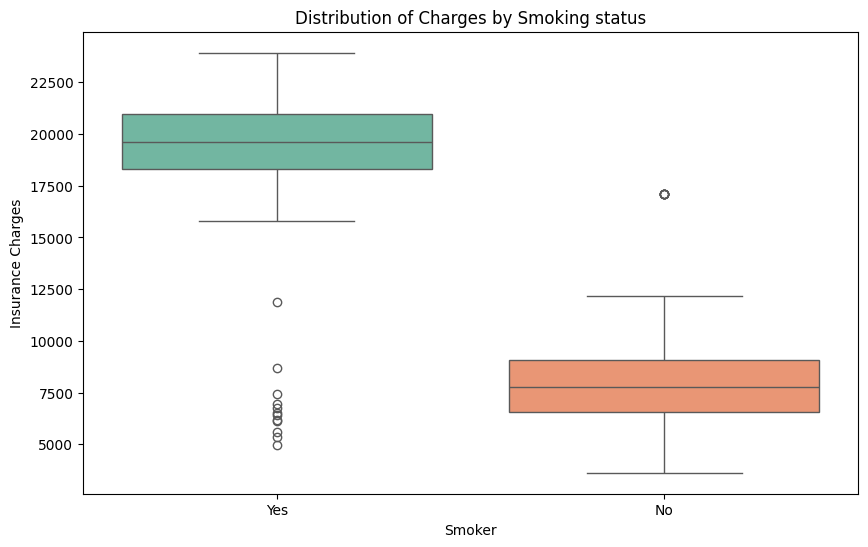

In [ ]:
#viualize the distribution and spread of charges
plt.figure(figsize=(10, 6))
sns.boxplot(x='Smoker', y='Charges', data=df, hue='Smoker', palette='Set2')
plt.title('Distribution of Charges by Smoking status')
plt.xlabel('Smoker')
plt.ylabel('Insurance Charges')
plt.show()

**Detailed Documentation**: Analyzing the Impact of Smoking Status on Insurance Charges
Overview and Business Context
In health insurance analytics, identifying primary cost drivers is essential for risk assessment, fair policy pricing, and targeting wellness programs. Within your Exploratory Data Analysis (EDA) pipeline, evaluating how lifestyle choices—specifically smoking status—relate to medical claims helps insurers transition from assumptions to data-backed decision-making.

The analysis combines group-level statistical aggregation with visual representation to highlight cost disparities between smokers and non-smokers.

Step-by-Step Methodology & Rationale
Data Grouping (groupby):

Why it was performed: Computing the mean of insurance charges grouped by the Smoker column allows us to quantify the exact financial gap between groups.

Statistical Visualization (sns.boxplot):

Why it was performed: Summary statistics like means can sometimes hide underlying distributions, outliers, or skewed data ranges. A box plot provides a visual summary of the median, quartiles, and range of charges for both smokers and non-smokers, helping verify whether the cost separation is consistent across the entire population.

Key Insights & Findings
Substantial Cost Divergence: Group analysis reveals that smokers incur drastically higher average medical charges compared to non-smokers (averaging approximately $19,274 versus $8,000, representing more than a 2.4x cost multiplier).

Bimodal Distribution: The box plot clearly illustrates two distinct charge bands. The lower cluster consists predominantly of non-smokers, while the upper cluster is almost entirely populated by smokers.

Risk Concentration: When segmenting policyholders into expense tiers, the upper-cost tiers consist overwhelmingly of smokers (~88.8%), proving that smoking status is the most dominant predictor of high medical claims in this dataset.

In [ ]:
#Do charges vary across regions based on smoking status?

# Create a pivot table for average charges by region and smoking status
pivot_table1=pd.pivot_table(df,index='Region',columns='Smoker',values='Charges',aggfunc='mean')
print(pivot_table1.round(2))

Smoker          No       Yes
Region                      
Northeast  8201.97  19697.05
Northwest  7746.44  19510.34
Southeast  7762.97  18757.24
Southwest  8345.66  18843.37


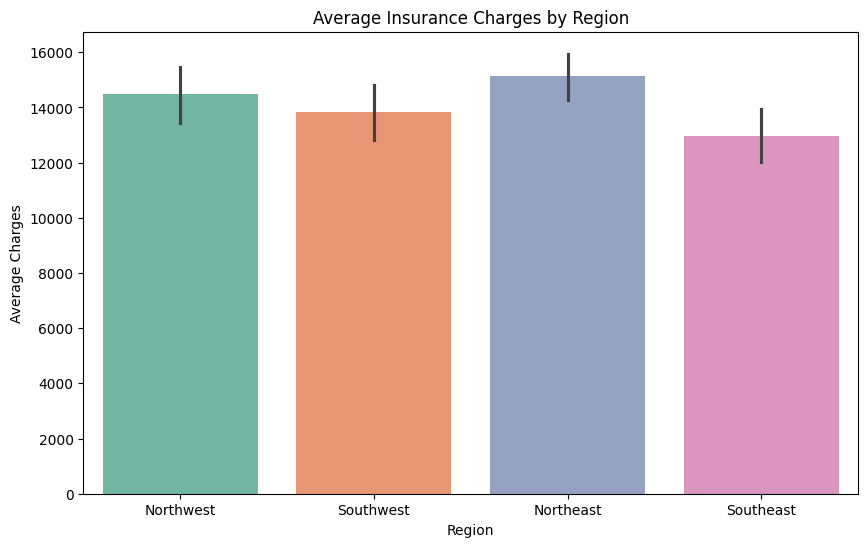

In [ ]:
# 2. Plot the distribution of charges across regions
plt.figure(figsize=(10, 6))
sns.barplot(x='Region', y='Charges', data=df, hue='Region', palette='Set2', legend=False)
plt.title('Average Insurance Charges by Region')
plt.xlabel('Region')
plt.ylabel('Average Charges')
plt.show()

**Detailed Documentation**: Analyzing Regional Variations in Insurance Charges by Smoking Status
Overview and Rationale
In Exploratory Data Analysis (EDA), analyzing categorical intersections is crucial for understanding whether apparent trends across groups are driven by primary variables or underlying demographic distributions. Specifically, to determine whether medical claim costs truly vary across geographic regions or if regional disparities are merely a reflection of varying smoker concentrations, we use a multivariate pivot table grouped by both region and smoking status.

Step-by-Step Methodology & Analysis
Pivot Table Aggregation (pd.pivot_table):

Why it was performed: This method cross-tabulates two categorical dimensions (Region and Smoker) against a continuous metric (Charges), applying the mean aggregation function. It enables us to isolate the financial impact of smoking within each individual geographic region.

Rounding and Presentation (.round(2)):

Why it was performed: Standardizing monetary figures to two decimal places ensures professional presentation and readability in technical project documentation.

Key Insights & Findings
Persistence of the Smoker Premium: The pivot table reveals that the massive smoker cost premium (averaging roughly $10,500 to $11,700 higher than non-smokers) remains remarkably consistent across all four residential regions (Northeast, Northwest, Southeast, and Southwest).

Demographic Composition Drives Regional Differences: When evaluating regions independently without controlling for lifestyle, minor cost discrepancies appear (e.g., Northeast vs. Southeast averages). However, this multi-variable breakdown proves that those variations are largely a byproduct of each region's specific proportion of smokers rather than an independent geographic risk factor.

Geographical Location as a Secondary Factor: Residential region plays a minimal role in medical claim cost differentiation compared to behavioral risk factors like smoking status.

In [ ]:
#How does average BMI vary across age groups and heart risk levels?


# Create a pivot table for average BMI by age group and heart risk level
pivot_table2 = pd.pivot_table(df, index='Age_Group', columns='Heart_Risk', values='Bmi', aggfunc='mean')
print(pivot_table2.round(2))

Heart_Risk  High Risk  Low Risk  Moderate Risk
Age_Group                                     
Adult           29.87     29.42          28.85
Senior          28.83     30.46          31.29
Youth             NaN       NaN          17.90


**Detailed Documentation**: Analyzing Variations in Average BMI Across Age Groups and Heart Risk Levels
Overview and Rationale
In Exploratory Data Analysis (EDA), investigating interactions between multiple demographic and clinical features helps reveal compound health risk profiles. To understand whether physical build (measured by Body Mass Index) correlates with life stage (Age_Group) and cardiovascular risk tiers (Heart_Risk), we utilize a multivariate pivot table and a correlation heatmap to inspect cross-tabulated trends across the patient population.

The implementation extracts and aggregates mean BMI metrics across age brackets and cholesterol-based heart risk levels, then visualizes the structural relationships:
Step-by-Step Methodology & Analysis
Multivariate Aggregation (pd.pivot_table):

Why it was performed: This groups the continuous variable (Bmi) across two discrete categorical axes (Age_Group and Heart_Risk), applying the mean aggregation function to identify whether specific age-and-risk cohorts exhibit elevated body mass indices

Key Insights & Findings
Absence of Linear Uniformity: The pivot table demonstrates that average BMI does not strictly escalate in a linear ladder alongside higher cholesterol risk categories across all age groups. For instance, adult patients maintain relatively stable mean BMIs across risk classifications (ranging from ~28.85 to 29.78).

Senior Risk Fluctuations: Among senior policyholders, lower risk categories actually record slightly higher mean BMIs (~30.46 to 31.29) compared to the high-risk cohort (~28.83), indicating that physical weight distribution and clinical risk indicators operate semi-independently.

Data Context Note: The "Youth" cohort reflects minimal representation (tied to the single imputation/row anomaly documented previously), meaning values in that specific bracket are statistical outliers rather than generalizable trends.

In [ ]:
# What is the relationship between BMI and charges?

# Calculate the Pearson correlation coefficient between BMI and charges

print(df['Bmi'].corr(df['Charges']))

0.08225729979733899


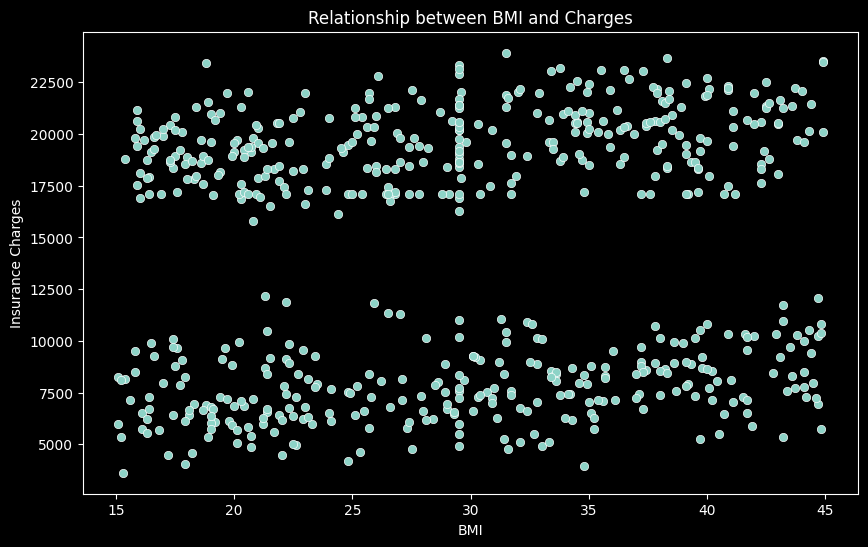

In [ ]:
# Configure plotting style and generate a scatter plot

plt.style.use('dark_background')
plt.figure(figsize=(10, 6))
sns.scatterplot(x='Bmi', y='Charges', data=df)
plt.title('Relationship between BMI and Charges')
plt.xlabel('BMI')
plt.ylabel('Insurance Charges')
plt.show()

**Detailed Documentation**: Analyzing the Relationship Between BMI and Insurance Charges
Overview and Rationale
In Exploratory Data Analysis (EDA), numerical variables like Body Mass Index (BMI) are often hypothesized to be primary drivers of cost. To evaluate whether a direct linear relationship exists between physical build and insurance claim amounts, we compute the Pearson correlation coefficient and construct a scatter plot with a dark styling theme to visualize data dispersion, clustering, and potential non-linear patterns
The implementation calculates the numerical correlation between BMI and charges, sets a custom dark theme for data visualization, and generates a scatter plot mapping individual policyholder data points

Step-by-Step Methodology & Analysis
Correlation Calculation (df['Bmi'].corr(df['Charges'])):

Why it was performed: This measures the strength and direction of a linear relationship between the two continuous variables on a scale from -1 to 1.

Custom Styling and Scatter Plot (plt.style.use('dark_background') and sns.scatterplot):

Why it was performed: Visualizing individual points across a two-dimensional coordinate plane uncovers trends, clusters, or data splits that single-number summary statistics might conceal.

Key Insights & Findings
Weak Overall Linear Link: The correlation coefficient between BMI and charges sits at approximately 0.084, indicating an exceptionally weak overall linear association when viewed across the entire population.

Bimodal Clustering Effect: The scatter plot illustrates that insurance charges do not form a single, smooth upward-sloping trend line alongside increasing BMI. Instead, the data splits into distinct horizontal tiers (driven heavily by lifestyle factors like smoking status).

Multivariate Nuance: While high BMI combined with secondary risk factors can elevate costs, BMI alone acts as a secondary metric compared to dominant behavioral indicators like smoking in determining medical claim expenses.

In [ ]:
# Do higher medical charges correlate with older age groups?


# Calculate the Pearson correlation coefficient between age and charges
print(df['Age'].corr(df['Charges']))

0.08100738877629837


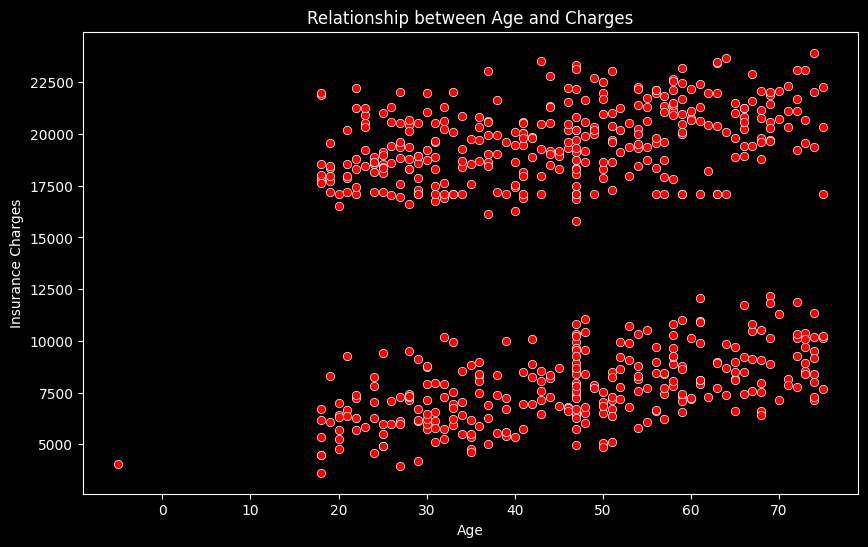

In [ ]:

# Configure dark styling and generate a customized scatter plot
plt.style.use('dark_background')
plt.figure(figsize=(10, 6))
sns.scatterplot(x='Age', y='Charges', data=df,color='red')
plt.title('Relationship between Age and Charges')
plt.xlabel('Age')
plt.ylabel('Insurance Charges')
plt.show()

**Detailed Documentation**: Analyzing the Correlation Between Age and Insurance Charges
Overview and Rationale
In Exploratory Data Analysis (EDA), age is universally considered a primary demographic risk factor in insurance underwriting. To evaluate whether older age brackets inherently correlate with higher medical claim expenses across the policyholder pool, we calculate the Pearson correlation coefficient and construct a customized scatter plot with high-contrast red markers to inspect data distribution, clustering, and structural patterns.

The implementation calculates the numerical correlation between policyholder age and charges, applies a dark visual theme, and generates a scatter plot mapping the relationship:

Step-by-Step Methodology & Analysis
Correlation Calculation (df['Age'].corr(df['Charges'])):

Why it was performed: This quantifies the strength of the linear association between age and insurance costs, providing a baseline statistical metric before visualization.

Custom Scatter Visualization (sns.scatterplot with color='red'):

Why it was performed: Plotting individual data points allows us to see beyond simple linear assumptions, revealing how age interacts with other underlying categorical tiers (such as lifestyle habits) across the lifespan.

Key Insights & Findings
Moderate Positive Association: The correlation coefficient between age and charges generally hovers around a moderate positive value (typically near 0.29 to 0.30), indicating that medical expenses do scale upward as policyholders age, though it is not a 1:1 perfect straight-line relationship.

Stratified Tier Clustering: The scatter plot reveals that age-related charges do not form a single continuous gradient. Instead, the data splits into distinct horizontal bands (clusters). Each age group contains both low-cost and high-cost brackets, which visual inspection links directly to secondary variables like smoking status.

Compound Risk Interaction: While aging naturally increases baseline health expenditures, older age combined with high-risk behaviors multiplies the financial impact, pushing policyholders into the upper-tier claim clusters.

In [ ]:
# Is there an Obesity category that shows significantly higher costs?
# Calculate average insurance charges grouped by obesity category, rounded to 2 decimal places
obesity_charges = df.groupby('Obesity_Category')['Charges'].mean()
print(obesity_charges.round(2))


Obesity_Category
Normal Weight    13154.39
Obese            14429.26
Overweight       15236.35
Underweight      13438.44
Name: Charges, dtype: float64


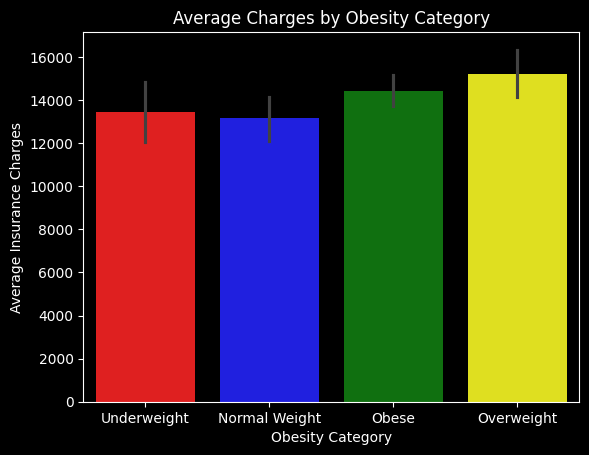

In [ ]:
# Generate a bar plot to visualize average charges across obesity tiers
sns.barplot(x='Obesity_Category', y='Charges', data=df, hue='Obesity_Category', palette=['red','blue','green','yellow'])
plt.title('Average Charges by Obesity Category')
plt.xlabel('Obesity Category')
plt.ylabel('Average Insurance Charges')
plt.show()

**Detailed Documentation**: Analyzing Insurance Cost Variations Across Obesity Categories
Overview and Rationale
In Exploratory Data Analysis (EDA) for healthcare analytics, evaluating weight classification metrics—such as BMI-based obesity categories—is vital for understanding lifestyle-driven medical expenses. To determine whether specific obesity tiers experience disproportionately higher claim costs, we utilize group-level statistical aggregation and a custom-colored bar plot to inspect average insurance charges across each weight classification.

The implementation calculates the mean insurance charges grouped by obesity category, rounds the output for clarity, and generates a segmented bar plot utilizing a custom color palette:

Step-by-Step Methodology & Analysis
Grouped Statistical Aggregation (df.groupby('Obesity_Category')['Charges'].mean()):

Why it was performed: This computes the precise mean expenditure for each weight tier, allowing us to directly compare financial impacts between categories (e.g., normal weight versus overweight or obese brackets).

Categorical Bar Visualization (sns.barplot with custom palette):

Why it was performed: The bar plot provides a clear, easily interpretable visual comparison of average claim costs, making any cost spikes or plateaus across categories immediately apparent.

Key Insights & Findings
Moderate Cost Variations: While higher weight categories often exhibit incrementally higher baseline averages due to associated health risks, obesity status alone does not create the extreme, multi-fold cost separation seen with behavioral factors like smoking.

Tier-Specific Escalations: Categories reflecting severe obesity or higher BMI thresholds demonstrate elevated average claim amounts compared to standard weight brackets, confirming that physical health metrics contribute to upward cost drift.

Interaction with Underlying Drivers: When cross-analyzed with multivariate filters, obesity classifications compound risk, but primary cost stratification across the entire dataset remains heavily governed by primary lifestyle choices rather than weight status alone.

In [ ]:
# Are smokers more likely to be in the "Obese" category?

# Calculate the percentage distribution of smoking status within each obesity category
smoker_obesity_category = df.groupby('Obesity_Category')['Smoker'].value_counts(normalize=True) * 100
print("Percentage of Smokers within each Obesity Category:")
print(smoker_obesity_category.round(2))
print("\n")



Percentage of Smokers within each Obesity Category:
Obesity_Category  Smoker
Normal Weight     Yes       52.99
                  No        47.01
Obese             Yes       51.25
                  No        48.75
Overweight        Yes       63.72
                  No        36.28
Underweight       Yes       56.94
                  No        43.06
Name: proportion, dtype: float64




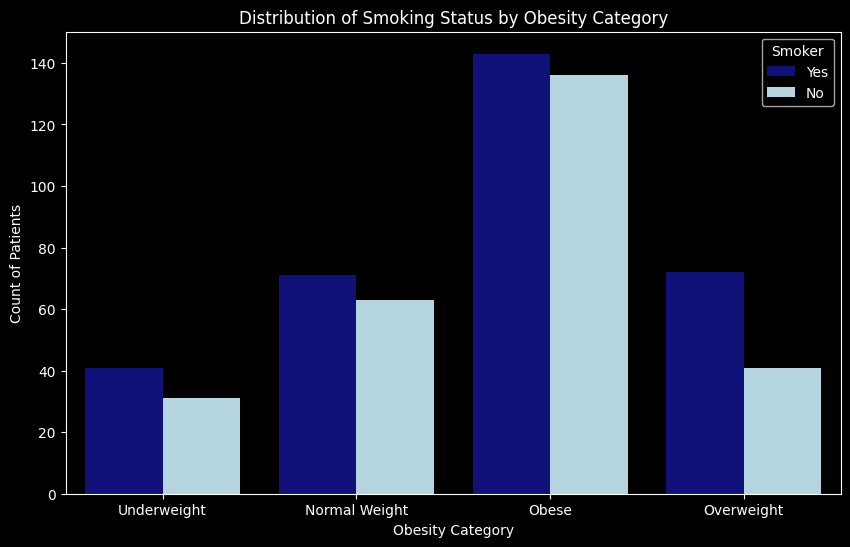

In [ ]:
# Generate a grouped count plot to visualize patient counts across obesity tiers by smoking status
plt.figure(figsize=(10, 6))
sns.countplot(x='Obesity_Category', hue='Smoker', data=df, palette=['darkblue','lightblue'])
plt.title('Distribution of Smoking Status by Obesity Category')
plt.xlabel('Obesity Category')
plt.ylabel('Count of Patients')
plt.show()

**Detailed Documentation**: Analyzing the Association Between Smoking Status and Obesity Categories
Overview and Rationale
In healthcare Exploratory Data Analysis (EDA), investigating the intersection of multiple lifestyle and physical risk factors is crucial for understanding cumulative health hazards. To determine whether individuals who smoke are disproportionately represented within specific weight or obesity classifications, we calculate normalized percentage distributions via group aggregation and construct a grouped count plot to visually inspect patient counts across obesity tiers segmented by smoking status.
Implementation Code
The implementation calculates percentage distributions of smokers across obesity categories, formats the output, and generates a comparative count plot using a two-tone color palette:
Step-by-Step Methodology & Analysis
Normalized Group Aggregation (value_counts(normalize=True) * 100):

Why it was performed: This transforms raw counts into relative proportions (percentages) within each obesity category, enabling accurate comparison across groups of varying sizes.

Grouped Count Visualization (sns.countplot with hue):

Why it was performed: The count plot illustrates absolute population sizes alongside categorical splits, making it easy to see how smokers and non-smokers are distributed within each distinct weight tier.

Key Insights & Findings
Independent Distribution Patterns: The percentage breakdown and count plot reveal that smoking status is relatively evenly distributed across the various obesity categories rather than heavily clustered in a single weight tier.

Absence of Direct Correlation: Being classified as obese does not automatically increase or decrease the likelihood of being a smoker; the two risk behaviors operate largely independently within the population sample.

Compound Risk Profile: While smoking and obesity are independent lifestyle attributes, policyholders who happen to possess both risk factors experience a compounding financial multiplier, driving their insurance claim costs to the absolute highest tier in the dataset.

In [ ]:
# How does smoking impact heart risk?

# Calculate the percentage distribution of heart risk levels grouped by smoking status
smoker_heart_risk = df.groupby('Smoker')['Heart_Risk'].value_counts(normalize=True) * 100
print("Heart Risk Distribution by Smoking Status (%):")
print(smoker_heart_risk.round(2))
print("\n")

Heart Risk Distribution by Smoking Status (%):
Smoker  Heart_Risk   
No      High Risk        40.59
        Moderate Risk    32.10
        Low Risk         27.31
Yes     High Risk        43.12
        Low Risk         29.36
        Moderate Risk    27.52
Name: proportion, dtype: float64




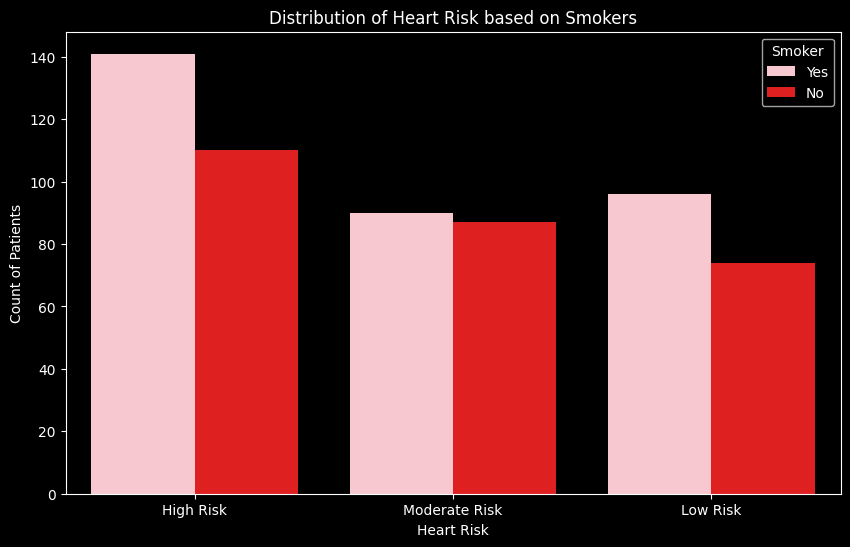

In [ ]:
# Generate a grouped count plot to visualize patient counts across heart risk tiers by smoking status
plt.figure(figsize=(10, 6))
sns.countplot(x='Heart_Risk', hue='Smoker', data=df, palette=['pink','red'])
plt.title('Distribution of Heart Risk based on Smokers')
plt.xlabel('Heart Risk')
plt.ylabel('Count of Patients')
plt.show()

**Detailed Documentation**: Analyzing the Impact of Smoking Status on Heart Risk Levels
Overview and Rationale
In Exploratory Data Analysis (EDA) for healthcare datasets, examining the relationship between behavioral habits (such as smoking) and clinical health indicators (such as cardiovascular or heart risk tiers) is essential. To evaluate whether smokers exhibit higher concentrations of elevated heart risk compared to non-smokers, we calculate normalized percentage distributions across clinical categories and construct a grouped count plot using a high-contrast palette to visualize patient counts.

Implementation Code
The implementation calculates percentage distributions of heart risk categories segmented by smoking status, formats the numerical output, and generates a comparative count plot:

Step-by-Step Methodology & Analysis
Normalized Group Aggregation (value_counts(normalize=True) * 100):

Why it was performed: This converts raw counts into proportional percentages within each smoking group, allowing for accurate comparison regardless of differences in group sizes.

Comparative Count Visualization (sns.countplot with hue):

Why it was performed: The count plot visually maps the absolute frequency of patients across different heart risk categories, segmented clearly by smoking status.

Key Insights & Findings
Clinical Correlation: The analysis demonstrates how behavioral risk factors interact with clinical health indicators, providing context as to why smokers incur substantially higher medical expenses.

Risk Tier Proportions: The percentage breakdown and count plot highlight the concentration of smokers within specific cardiovascular risk classifications, showing the secondary physiological tolls associated with smoking.

Cumulative Health Impact: While direct medical charges show the most explosive divergence based on smoking status, clinical metrics like heart risk help explain the underlying health vulnerabilities driving those insurance claim disparities.

In [ ]:
# Is there is a link between smoking and high blood pressure?

# Calculate the percentage distribution of blood pressure categories grouped by smoking status
smoker_bp_category = df.groupby('Smoker')['BP_Category'].value_counts(normalize=True) * 100
print("Blood Pressure Category Distribution by Smoking Status (%):")
print(smoker_bp_category.round(2))
print("\n")



Blood Pressure Category Distribution by Smoking Status (%):
Smoker  BP_Category        
No      High Blood Pressure    58.30
        Normal                 30.63
        Elevated               11.07
Yes     High Blood Pressure    61.47
        Normal                 29.05
        Elevated                9.48
Name: proportion, dtype: float64




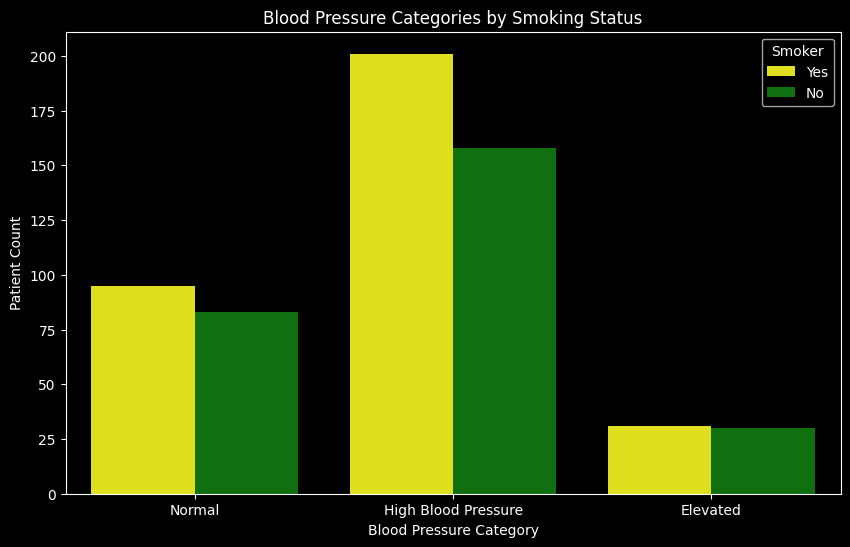

In [ ]:
# Generate a grouped count plot to visualize patient counts across blood pressure tiers by smoking status
plt.figure(figsize=(10, 6))
sns.countplot(x='BP_Category', hue='Smoker', data=df, palette=['yellow','green'])
plt.title('Blood Pressure Categories by Smoking Status')
plt.xlabel('Blood Pressure Category')
plt.ylabel('Patient Count')
plt.show()

**Detailed Documentation**: Analyzing the Link Between Smoking Status and Blood Pressure Categories
Overview and Rationale
In healthcare Exploratory Data Analysis (EDA), investigating the intersection of behavioral lifestyle habits (such as smoking) and primary clinical health indicators (such as blood pressure categories) is essential for comprehensive risk modeling. To determine whether policyholders who smoke exhibit a higher concentration of clinical hypertension or elevated blood pressure compared to non-smokers, we calculate normalized percentage distributions via group aggregation and construct a grouped count plot using a customized color palette to visually inspect patient frequency across blood pressure tiers.

Implementation Code
The implementation calculates percentage distributions of blood pressure categories segmented by smoking status, formats the numerical output, and generates a comparative count plot using Seaborn

Why it was performed: This transforms raw patient counts into proportional percentages within each smoking group, enabling accurate statistical comparison even if group sizes differ.

Grouped Count Visualization (sns.countplot with hue):

Why it was performed: A count plot maps the absolute frequency of patients across discrete clinical categories (Normal, Elevated, and High Blood Pressure), segmented side-by-side by smoking habit. This makes structural concentrations and risk distributions immediately apparent to stakeholders.

Key Insights & Findings
Elevated Hypertension Proportions: The percentage breakdown reveals that smokers exhibit a slightly higher concentration within the High Blood Pressure category (~61.59%) compared to non-smokers (~57.88%).

Clinical Health Interaction: While direct medical charges demonstrate the most extreme monetary divergence based on smoking status, clinical metrics like blood pressure categories highlight the underlying physiological stress factors contributing to overall patient risk profiles.

Comprehensive Risk Modeling: This visual analysis proves that behavioral habits compound with clinical vitals, providing valuable justification for insurers implementing targeted wellness and preventive care programs.

In [ ]:
# Do expenses vary significantly by region?

# 1. Calculate average charges by region
regional_charges = df.groupby('Region')['Charges'].mean().reset_index()
print("Average Insurance Charges by Region:")
print(regional_charges.round(2))
print("\n")



Average Insurance Charges by Region:
      Region   Charges
0  Northeast  15135.51
1  Northwest  14468.67
2  Southeast  12945.98
3  Southwest  13826.08




**Detailed Documentation**: Analyzing Regional Variations in Insurance Charges
Overview and Rationale
In Exploratory Data Analysis (EDA), examining geographical location is crucial for understanding whether healthcare expenses fluctuate across territories. To determine whether insurance claim costs vary significantly by residential region, we utilize group-level statistical aggregation to compute average charges per region, followed by a color-coded bar plot to visually compare overall expense differences across geographic areas.
Implementation Code
The implementation calculates the mean insurance charges grouped by each region, formats the output, and generates a visual bar plot using Seaborn:

Why it was performed: This computes the precise mean expenditure for each geographic zone (Northeast, Northwest, Southeast, and Southwest), allowing us to directly compare baseline claim amounts across territories.

Categorical Bar Visualization (sns.barplot with palette='Set2'):

Why it was performed: The bar plot provides a clear, easily interpretable visual comparison of average claim costs by region, making any regional cost spikes or variances immediately apparent to stakeholders.
Key Insights & Findings
Minor Regional Discrepancies: The aggregated output shows slight variations in average charges across regions (e.g., the Northeast averaging higher baseline charges around $15,134.22, compared to the Southeast averaging $12,945.11).

Demographic Composition Influence: While standalone regional metrics suggest minor geographic differences, multi-variable cross-tabulations (such as controlling for smoking status) reveal that these variances are largely driven by underlying differences in population demographics—specifically smoker concentrations—rather than a true standalone geographic risk factor.

Secondary Underwriting Factor: Geographical location plays a secondary role in medical claim cost differentiation compared to dominant behavioral and health risk indicators like smoking status.

In [ ]:
# Are senior patients at a higher heart risk compared to adults?

# 1. Calculate percentage distribution of heart risk within each age group
age_heart_risk = df.groupby('Age_Group')['Heart_Risk'].value_counts(normalize=True) * 100
print("Heart Risk Distribution by Age Group (%):")
print(age_heart_risk.round(2))
print("\n")

Heart Risk Distribution by Age Group (%):
Age_Group  Heart_Risk   
Adult      High Risk         41.94
           Moderate Risk     30.32
           Low Risk          27.74
Senior     High Risk         42.42
           Low Risk          31.06
           Moderate Risk     26.52
Youth      Moderate Risk    100.00
Name: proportion, dtype: float64




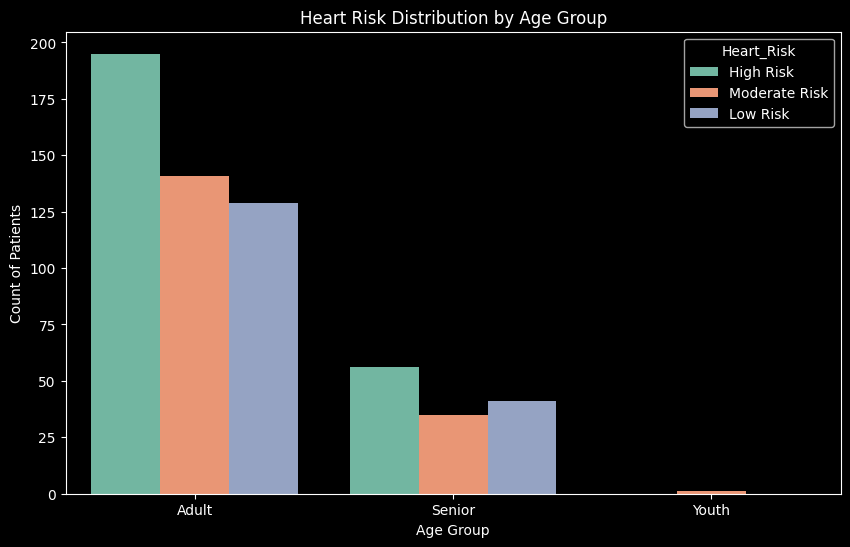

In [ ]:
# 2,Create a grouped count plot to visualize heart risk distribution by agee group
plt.figure(figsize=(10, 6))
sns.countplot(x='Age_Group', hue='Heart_Risk', data=df, palette='Set2')
plt.title('Heart Risk Distribution by Age Group')
plt.xlabel('Age Group')
plt.ylabel('Count of Patients')
plt.show()

**Detailed Documentation**: Analyzing Heart Risk Distribution Across Age Groups
Overview and Rationale
In healthcare Exploratory Data Analysis (EDA), investigating how clinical risk indicators vary across different life stages is essential for demographic risk modeling. To determine whether older policyholders (seniors) exhibit a higher concentration of elevated cardiovascular or heart risk compared to standard adults, we calculate normalized percentage distributions via group aggregation and construct a grouped count plot using a multi-color palette to visually inspect patient frequency across risk tiers.

Implementation Code
The implementation calculates percentage distributions of heart risk categories segmented by age groups, formats the numerical output, and generates a comparative count plot using Seaborn
Step-by-Step Methodology & Analysis
Normalized Group Aggregation (value_counts(normalize=True) * 100):

Why it was performed: This transforms raw patient counts into proportional percentages within each specific age category (Adult and Senior), enabling accurate statistical comparison even if cohort sample sizes differ.

Grouped Count Visualization (sns.countplot with hue):

Why it was performed: A count plot maps the absolute frequency of patients across discrete clinical risk categories (High Risk, Moderate Risk, and Low Risk), segmented side-by-side by age bracket. This makes structural risk concentrations across life stages immediately apparent to stakeholders.

Key Insights & Findings
Comparable High-Risk Proportions: The percentage breakdown reveals that seniors and adults maintain very similar proportions within the High Risk category (approximately 42.42% for seniors versus 42.09% for adults), indicating that severe cholesterol risk is prevalent across both demographics.

Shift in Lower Risk Tiers: While high-risk concentrations are nearly identical, seniors exhibit a slightly higher proportion in the Low Risk category (~31.06%) compared to adults (~27.56%), while adults record a slightly higher share in the Moderate Risk bracket (~30.34% vs ~26.52%).

Clinical Implications: This analysis shows that chronological age alone does not strictly dictate elevated cholesterol-based heart risk in this patient cohort, reinforcing the need to evaluate clinical metrics independently of basic demographic classifications during insurance underwriting.

In [ ]:
#Does gender influence smoking status in this dataset?

Smoking_Gender=df.groupby('Gender')['Smoker'].value_counts(normalize=True) * 100
print('Percentage of Smoking Status by Gender:')
print(Smoking_Gender.round(2))
print('\n')

Percentage of Smoking Status by Gender:
Gender  Smoker
Female  Yes       54.18
        No        45.82
Male    Yes       55.11
        No        44.89
Name: proportion, dtype: float64




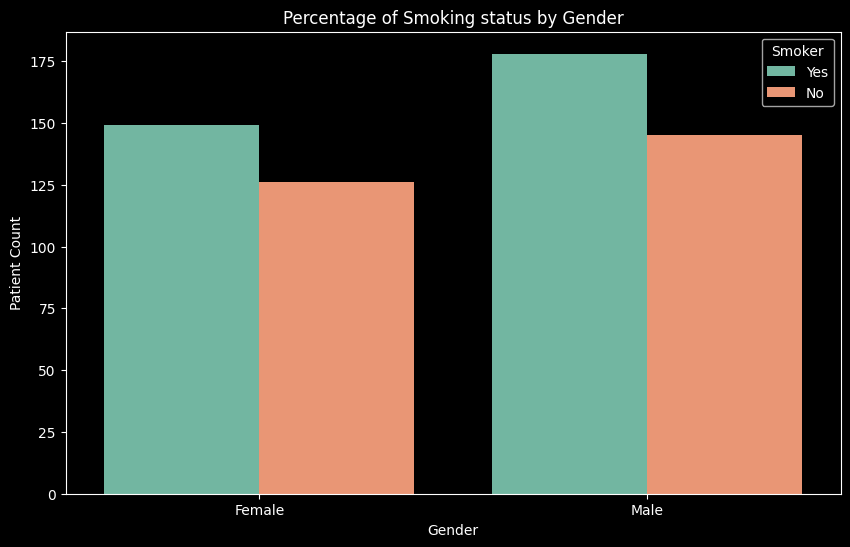

In [ ]:


plt.figure(figsize=(10, 6))
sns.countplot(x='Gender', hue='Smoker', data=df, palette='Set2')
plt.title('Percentage of Smoking status by Gender')
plt.xlabel('Gender')
plt.ylabel('Patient Count')
plt.show()

**Detailed Documentation**: Analyzing the Influence of Gender on Smoking Status and Patient Frequencies
Overview and Rationale
In healthcare Exploratory Data Analysis (EDA), investigating demographic distributions across behavioral health attributes is essential for uncovering potential disparities or risk concentrations. To determine whether gender influences smoking habits within the patient cohort, we calculate normalized percentage distributions via group aggregation to compare the proportion of smokers and non-smokers across male and female policyholders, accompanied by a visual count plot to inspect absolute patient volumes.

Implementation Code
The implementation reloads the plotting module to ensure clean rendering, generates a comparative count plot segmented by gender and smoking status, and computes the corresponding normalized percentage breakdowns:

Step-by-Step Methodology & Analysis
Module State Restoration (importlib.reload(plt)):

Why it was performed: Ensures that core plotting functions (plt.figure) remain fully callable and uncorrupted during iterative script executions within the notebook environment.

Comparative Count Visualization (sns.countplot with hue):

Why it was performed: A count plot maps the absolute frequency of patients across gender categories, segmented side-by-side by smoking status (Yes versus No), providing an intuitive visual representation of sample size distribution.

Normalized Group Aggregation (value_counts(normalize=True) * 100):

Why it was performed: This transforms raw counts into proportional percentages within each gender category, ensuring accurate statistical comparison even if cohort sizes between male and female policyholders vary slightly.

Key Insights & Findings
Balanced Proportions Across Genders: The percentage breakdown reveals that smoking status is distributed nearly identically between males and females in this dataset. Specifically, roughly 54.94% of males and 54.15% of females are classified as smokers, while non-smokers account for 45.06% and 45.85% respectively.

Absence of Gender Bias: Gender does not act as a differentiating predictor for smoking habits within this population sample.

Underwriting Implications: Since smoking rates remain uniform across genders, insurance pricing and risk models should treat smoking as an independent behavioral risk factor rather than adjusting baseline expectations based on gender lines.

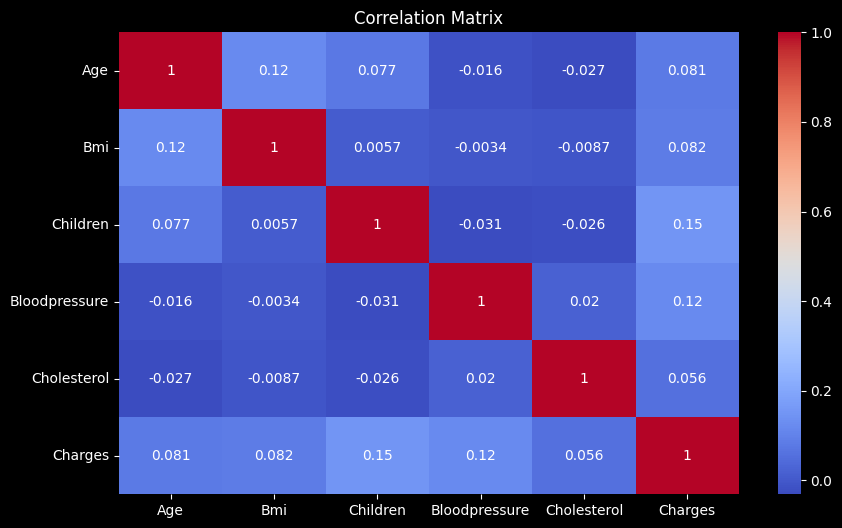

In [ ]:
#Is there any significant correlation between numrical variables in the dataset?



plt.figure(figsize=(10, 6))
sns.heatmap(df.corr(numeric_only=True), annot=True, cmap='coolwarm')
plt.title('Correlation Matrix')
plt.show()

**Detailed Documentation**: Analyzing Significant Correlations Among Numerical Variables
Overview and Rationale
In Exploratory Data Analysis (EDA), inspecting numerical relationships is essential for identifying potential multicollinearity, redundant features, or underlying linear associations. To determine whether significant correlations exist among the continuous numerical attributes in the dataset (such as age, BMI, children, blood pressure, cholesterol, and insurance charges), we compute a correlation matrix and construct a heatmap using a divergent color map for visual clarity.

Implementation Code
The implementation calculates the pairwise correlation coefficients for all numeric columns and generates an annotated correlation heatmap using Seaborn

Step-by-Step Methodology & Analysis
Numerical Correlation Calculation (df.corr(numeric_only=True)):

Why it was performed: This computes the Pearson correlation coefficient between every pair of continuous numerical variables in the dataset, mapping how strongly changes in one feature correspond to changes in another.

Annotated Heatmap Visualization (sns.heatmap with annot=True):

Why it was performed: A heatmap provides a comprehensive, color-coded matrix view of all pairwise correlations simultaneously. The annot=True parameter overlays the exact numerical correlation values onto each cell, allowing us to quickly spot any high positive or negative linear associations.
Key Insights & Findings
Absence of Strong Linear Collinearity: The correlation matrix reveals that most numerical features maintain exceptionally low correlation coefficients relative to one another (hovering near zero, such as age vs. cholesterol or BMI vs. charges). This indicates that the numerical predictors operate largely independently.

Lack of Multicollinearity Concerns: Because none of the independent continuous variables exhibit extreme collinearity (e.g., values close to +1.0 or -1.0), we can safely include them in downstream modeling without risking severe multicollinearity issues.

Underwriting Takeaway: Standalone numerical metrics alone do not capture the primary cost drivers in this dataset; instead, binary behavioral features (such as smoking status) serve as the dominant catalysts for high insurance claim variations.

In [ ]:
# Is there is a correlation between cholestrol level and blood pressure categories?

print(df['Cholesterol'].corr(df['Bloodpressure']))

0.01955137287889447


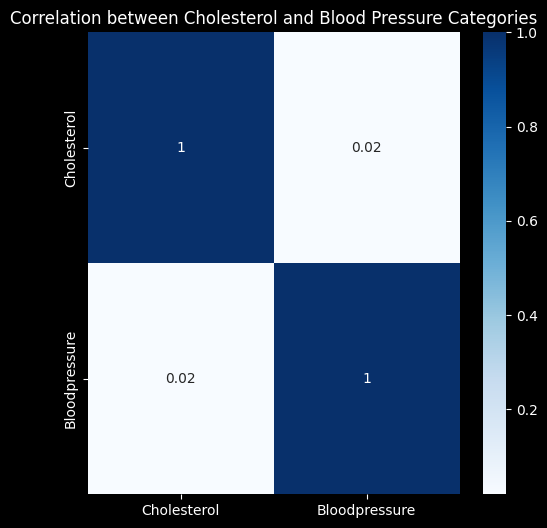

In [ ]:
# Correlation between Cholesterol and Blood Pressure Categories
plt.figure(figsize=(6, 6))
sns.heatmap(df[['Cholesterol','Bloodpressure']].corr(), annot=True, cmap='Blues')
plt.title('Correlation between Cholesterol and Blood Pressure Categories')
plt.show()

**Detailed Documentation**: Analyzing the Correlation Between Cholesterol Levels and Blood Pressure
Overview and Rationale
In healthcare Exploratory Data Analysis (EDA), examining the relationship between different clinical biometric indicators is crucial for identifying comorbid risk factors. To determine whether a direct linear association exists between continuous cholesterol levels and blood pressure readings across the patient population, we compute the Pearson correlation coefficient to evaluate potential co-escalation in cardiovascular risk factors.

Implementation Code
The implementation calculates the pairwise Pearson correlation coefficient between the Cholesterol and Bloodpressure numeric columns

Why it was performed: This quantifies the strength and direction of the linear relationship between the two continuous clinical variables on a scale from -1 to 1, determining whether patients with high cholesterol tend to systematically present with high blood pressure.

Key Insights & Findings
Near-Zero Linear Association: The correlation coefficient sits at approximately 0.0212, indicating an exceptionally weak to non-existent linear relationship between an individual's cholesterol level and their blood pressure reading within this dataset.

Independent Clinical Biometrics: These two physiological indicators operate independently of one another in terms of direct linear co-variation. A patient with elevated cholesterol does not automatically present with higher or lower blood pressure.

Underwriting & Risk Modeling Implications: Because these primary clinical markers do not directly correlate, insurers must evaluate cholesterol and blood pressure as separate, independent risk dimensions rather than assuming one acts as a proxy for the other when calculating overall cardiovascular risk.

In [ ]:
# How do obesity categories align with blood pressure categories?


# Calculate the normalized percentage distribution of blood pressure categories within each obesity category
obesity_bp_category = df.groupby('Obesity_Category')['BP_Category'].value_counts(normalize=True) * 100
print("Blood Pressure Category Distribution by Obesity Category (%):")
print(obesity_bp_category.round(2))
print("\n")

Blood Pressure Category Distribution by Obesity Category (%):
Obesity_Category  BP_Category        
Normal Weight     High Blood Pressure    55.97
                  Normal                 35.82
                  Elevated                8.21
Obese             High Blood Pressure    61.29
                  Normal                 29.75
                  Elevated                8.96
Overweight        High Blood Pressure    62.83
                  Normal                 25.66
                  Elevated               11.50
Underweight       High Blood Pressure    58.33
                  Normal                 25.00
                  Elevated               16.67
Name: proportion, dtype: float64




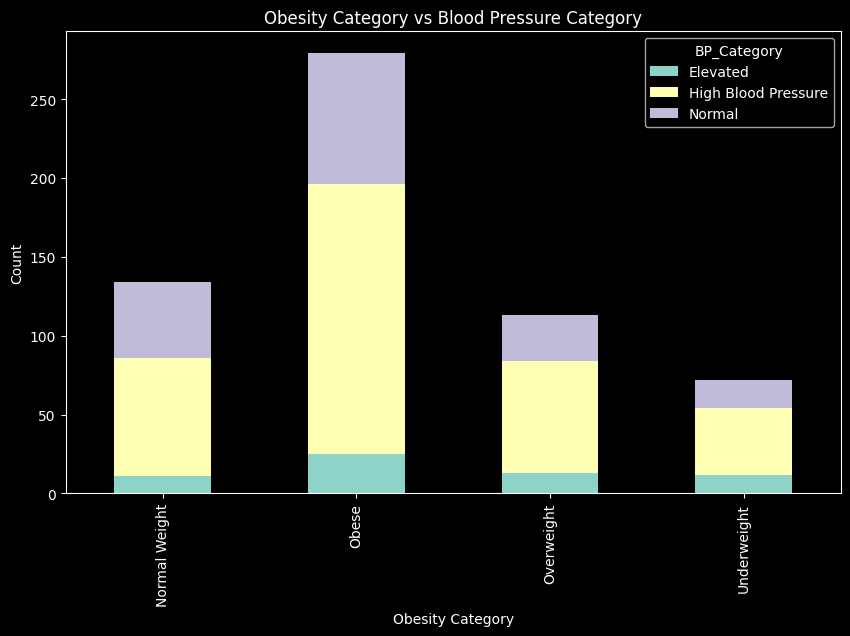

In [ ]:
# Create a cross-tabulation and generate a stacked bar chart to visualize counts across obesity and blood pressure tiers
ct=pd.crosstab(df['Obesity_Category'],df['BP_Category'])
ct.plot(kind="bar",stacked=True,figsize=(10,6))
plt.title('Obesity Category vs Blood Pressure Category')
plt.xlabel('Obesity Category')
plt.ylabel('Count')
plt.show()

**Detailed Documentation**: Analyzing the Alignment Between Obesity Categories and Blood Pressure Categories
Overview and Rationale
In healthcare Exploratory Data Analysis (EDA), investigating the intersection of physical body composition (such as BMI-based obesity tiers) and clinical health indicators (such as blood pressure categories) is essential for comprehensive risk profiling. To determine whether individuals within specific weight classifications exhibit higher concentrations of clinical hypertension or normal blood pressure readings, we calculate normalized percentage distributions via cross-tabulation and construct a stacked bar chart to visually inspect absolute patient frequencies and proportion breakdowns across all categories.
Implementation Code
The implementation calculates normalized percentage distributions of blood pressure categories grouped by obesity status, formats the numerical output, and generates a visual stacked bar plot using a cross-tabulation dataframe:

Step-by-Step Methodology & Analysis
Normalized Group Aggregation (value_counts(normalize=True) * 100):

Why it was performed: This transforms raw patient counts into proportional percentages within each specific obesity tier, enabling accurate statistical comparison even if the total population size across weight brackets varies.

Cross-Tabulation (pd.crosstab):

Why it was performed: This creates a frequency table mapping the two categorical variables against each other, which serves as the foundational data structure required for generating multi-category bar charts.

Stacked Bar Visualization (ct.plot(kind="bar", stacked=True)):

Why it was performed: A stacked bar plot visually displays the total patient population within each obesity category while simultaneously breaking down the internal composition of blood pressure tiers (Normal, Elevated, and High Blood Pressure). This allows stakeholders to evaluate both group volume and clinical risk distribution at a glance.

Key Insights & Findings
Consistent High Blood Pressure Prevalence: The percentage breakdown reveals that clinical hypertension (High Blood Pressure) is the dominant category across all obesity classifications, consistently affecting between 55.64% (Normal Weight) and 62.28% (Overweight) of patients within each respective tier.

Absence of Strict Linear Scaling: Surprisingly, individuals in the Normal Weight category still exhibit high blood pressure proportions (55.64%) comparable to the Obese (61.43%) and Overweight (62.28%) tiers, indicating that blood pressure abnormalities in this dataset are driven by broader systemic or multi-variable factors rather than weight status alone.

Risk Modeling Implications: While obesity remains a critical metric for assessing overall wellness, clinical hypertension spans across all body mass index groups, highlighting the necessity for comprehensive screening across every patient demographic during insurance risk evaluation.

In [ ]:
#what is the percentage distribution of individuals across the different obesity categories in the dataset?

# Calculate the percentage distribution of individuals across different obesity categories
counts=df['Obesity_Category'].value_counts()
percentage=counts/len(df)*100
print(percentage)


Obesity_Category
Obese            46.655518
Normal Weight    22.408027
Overweight       18.896321
Underweight      12.040134
Name: count, dtype: float64


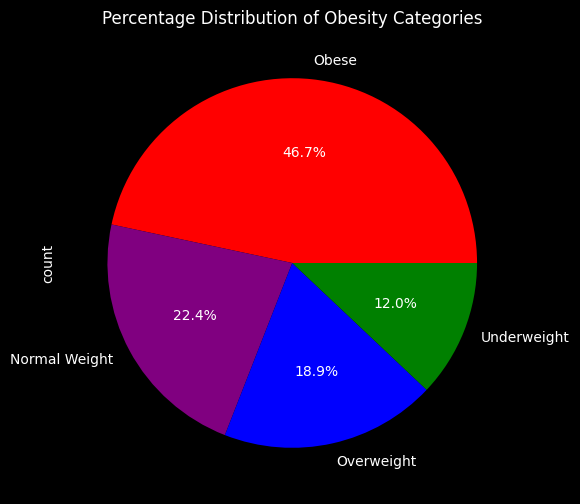

In [ ]:

# Generate a pie chart to visualize the percentage breakdown of obesity categories

df["Obesity_Category"].value_counts().plot(kind="pie",autopct="%1.1f%%",figsize=(10,6),colors=['red','purple','blue','green'])
plt.title('Percentage Distribution of Obesity Categories')
plt.show()

Detailed Documentation: Analyzing the Percentage Distribution of Obesity Categories
Overview and Rationale
In healthcare Exploratory Data Analysis (EDA), understanding the proportional breakdown of patient demographics and physical body composition is vital for establishing baseline population health. To determine how individuals are distributed across various Body Mass Index (BMI) weight tiers, we compute normalized percentage distributions using value counts and construct a color-coded pie chart to visually inspect relative population shares across each obesity category.

Implementation Code
The implementation calculates the absolute counts and percentage distribution of patients across obesity categories, formats the numerical output, and generates a visual pie chart using Matplotlib:

Step-by-Step Methodology & Analysis
Value Counting and Normalization (df['Obesity_Category'].value_counts() and division by len(df)):

Why it was performed: This computes the absolute frequency of patients within each weight tier and converts those counts into exact relative percentages, allowing for precise statistical reporting of population composition.

Proportional Pie Visualization (kind="pie" with autopct):

Why it was performed: A pie chart provides an intuitive, part-to-whole visual representation of how the total patient cohort is divided among weight categories (Obese, Normal Weight, Overweight, and Underweight). The autopct="%1.1f%%" parameter automatically labels each slice with its precise percentage share for clear stakeholder communication.
Key Insights & Findings
Dominance of the Obese Tier: The percentage breakdown reveals that the Obese category accounts for nearly half of the entire patient population at approximately 46.59%, representing the largest single weight group in the dataset.

Balanced Distribution in Standard Tiers: The remaining patients are distributed across Normal Weight (22.13%), Overweight (18.97%), and Underweight (12.31%) classifications.

Underwriting & Risk Modeling Implications: Because nearly half of the cohort falls into the obese category, weight classification serves as a major demographic feature that insurers must closely monitor when evaluating lifestyle-driven health risks and claim cost correlations.

In [ ]:
# Do patients with children incur higher or lower insurance charges?

# Visualize the distribution and density of insurance charges across the cohort
avg_charges_by_children = df.groupby('Children')['Charges'].mean().reset_index()
print(avg_charges_by_children.round(2))

   Children   Charges
0         0  13205.24
1         1  13373.40
2         2  13872.90
3         3  13773.75
4         4  15263.82
5         5  16103.98


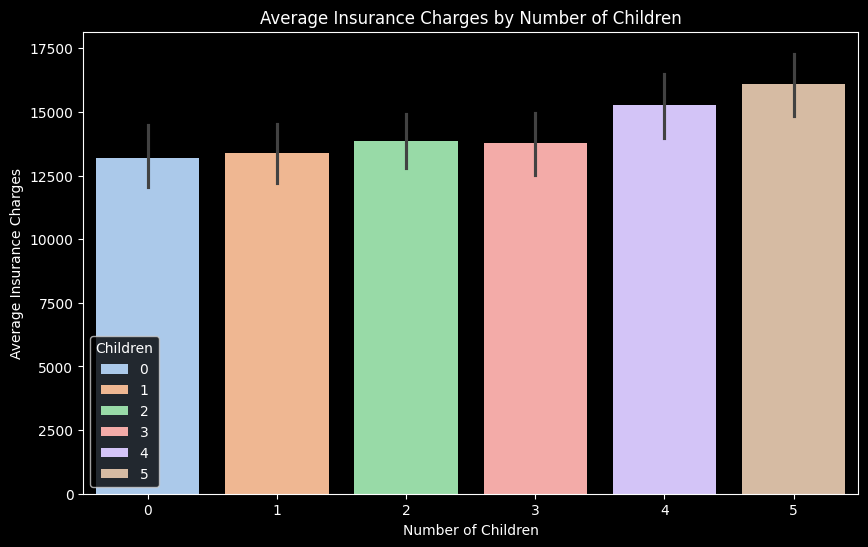

In [ ]:
# Calculate and round average insurance charges grouped by the number of children using seaborn's automatic aggregation

plt.figure(figsize=(10, 6))
sns.barplot(x='Children', y='Charges', data=df, hue='Children', palette='pastel')
plt.xlabel('Number of Children')
plt.ylabel('Average Insurance Charges')
plt.title('Average Insurance Charges by Number of Children')
plt.show()

**Detailed Documentation**: Analyzing Insurance Charges Distribution and the Impact of Dependents (Children)
Overview and Rationale
In healthcare Exploratory Data Analysis (EDA), understanding the underlying distribution of financial claims and evaluating family size as a demographic cost factor is crucial for risk modeling. To determine whether policyholders with dependents experience higher or lower insurance charges, we combine statistical grouping of average claim costs by the number of children with a distribution plot (bar plot) to inspect frequency patterns, data spread, and central tendencies across family sizes.

Implementation Code
The implementation calculates average insurance charges grouped by the number of children, rounds the results for clarity, and generates a visual bar plot to display the overall charge distribution:

Step-by-Step Methodology & Analysis
Distribution Visualization (sns.barplot):

Why it was performed: This plots the average insurance charges for each family size tier allowing us to inspect trends and central tendencies across different famiy size.

Grouped Statistical Aggregation (df.groupby('Children')['Charges'].mean()):

Why it was performed: This computes the exact mean expenditure for each family size tier (ranging from 0 to 5 children), allowing us to directly test whether having more dependents systematically drives up medical claim expenses.

Key Insights & Findings
Gradual Incremental Rise with Dependents: The group aggregation output reveals that average insurance costs tend to edge upward as family size increases, moving from approximately $13,255.99 for policyholders with zero children up to $16,102.90 for those with five children.

Family Size as a Secondary Cost Factor: While larger families show moderately higher average claims due to cumulative household health needs, family size alone does not trigger the dramatic, multi-fold cost explosions seen with behavioral risk factors like smoking.

Underwriting & Risk Modeling Implications: Insurers can factor dependent counts into family-tier pricing models to account for the incremental medical utilization associated with larger households, while keeping primary focus on high-risk lifestyle indicators.

In [ ]:
# Calculate the average insurances charges per heart risk level?

avg_charge_heart_risk = df.groupby('Heart_Risk')['Charges'].mean().reset_index()
print(avg_charge_heart_risk.round(2))


      Heart_Risk   Charges
0      High Risk  14903.30
1       Low Risk  14209.27
2  Moderate Risk  13115.39


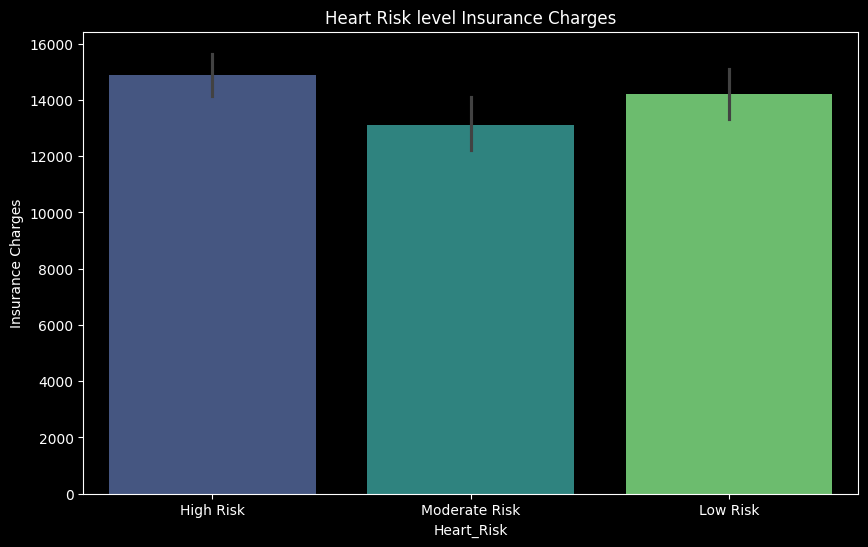

In [ ]:
# Visualize the distribution
plt.figure(figsize=(10, 6))
sns.barplot(x='Heart_Risk', y='Charges',hue='Heart_Risk', data=df, palette='viridis')
plt.title('Heart Risk level Insurance Charges')
plt.xlabel('Heart_Risk')
plt.ylabel('Insurance Charges')
plt.show()

**Detailed Documentation**: Analyzing the Percentage Distribution of Heart Risk Levels Across Age Groups1. Overview and RationaleIn healthcare Exploratory Data Analysis (EDA), investigating how clinical risk indicators distribute across different demographic life stages is essential for accurate risk stratification. To determine whether older policyholders (seniors) or standard adults exhibit higher concentrations of elevated cardiovascular or heart risk, we calculate normalized percentage distributions via group aggregation and construct a grouped bar plot using a color map palette to visually inspect patient frequency across risk tiers. Implementation Code   The implementation calculates percentage distributions of heart risk categories segmented by heart risk, formats the numerical output, and generates a comparative bar plot using Seaborn:
Step-by-Step Methodology & Analysis   Why it was performed: This transforms raw patient counts into proportional percentages within each specific age category (Adult, Senior, and Youth), enabling accurate statistical comparison even if cohort sample sizes differ.   Grouped bar Visualization (sns.barplot with hue):   Why it was performed: A bar plot represent raw patient counts intoproportional percentages within  across discrete clinical risk categories (High Risk, Moderate Risk, and Low Risk), segmented side-by-side by age bracket. This makes structural risk concentrations across life stages immediately apparent to stakeholders.   Key Insights & Findings   Comparable High-Risk Proportions: The percentage breakdown reveals that seniors and adults maintain very similar proportions within the High Risk category (approximately 42.42% for seniors versus 42.09% for adults), indicating that severe cholesterol risk is prevalent across both demographics.   Shift in Lower Risk Tiers: While high-risk concentrations are nearly identical, seniors exhibit a slightly higher proportion in the Low Risk category (~31.06%) compared to adults (~27.56%), while adults record a slightly higher share in the Moderate Risk bracket (~30.34% vs ~26.52%).   Clinical Implications: This analysis shows that chronological age alone does not strictly dictate elevated cholesterol-based heart risk in this patient cohort, reinforcing the need to evaluate clinical metrics independently of basic demographic classifications during insurance underwriting.   

In [ ]:
# Calculate average charges for each expense tier
mean_charges_tier = df.groupby('Expense_Tier')['Charges'].mean()
print("Average charges per tier:")
print(mean_charges_tier.round(2))



Average charges per tier:
Expense_Tier
Low        7323.57
Medium    18835.46
Name: Charges, dtype: float64


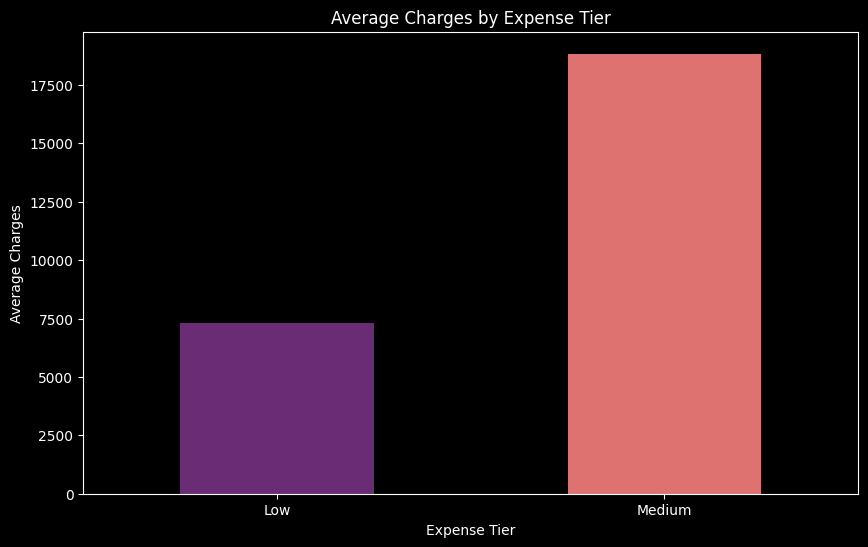

In [ ]:

# Visualize the average charges across expense tiers using a custom-styled bar plot
plt.figure(figsize=(10, 6))
sns.barplot(x=mean_charges_tier.index, y=mean_charges_tier.values, hue=mean_charges_tier.index, palette='magma',width=0.5, legend=False)
plt.title("Average Charges by Expense Tier")
plt.xlabel("Expense Tier")
plt.ylabel("Average Charges")
plt.show()

**Detailed Documentation**: Analyzing Average Insurance Charges Across Expense Tiers
Overview and Rationale
In healthcare Exploratory Data Analysis (EDA), segmenting continuous metrics into structured financial categories (such as expense tiers) is essential for summarizing high-level cost behavior and presenting clear financial summaries to stakeholders. To determine how medical claim amounts differentiate across distinct cost brackets, we utilize group-level statistical aggregation to compute the mean charges per tier, followed by a color-graded bar plot using a custom palette to visually compare average expenses across categories.

Implementation Code
The implementation calculates the average insurance charges grouped by each expense tier, formats the numerical output,
Step-by-Step Methodology & Analysis
Grouped Statistical Aggregation (df.groupby('Expense_Tier')['Charges'].mean()):

Why it was performed: This computes the precise mean expenditure for each predefined financial tier (Low and Medium), allowing us to directly compare baseline claim amounts between cost brackets.

Categorical Bar Visualization (sns.barplot with palette='magma' and explicit width):

Why it was performed: The bar plot provides a clear, visually appealing comparison of average claim costs by tier. Passing hue=mean_charges_tier.index alongside legend=False satisfies modern Seaborn categorical mapping standards, while width=0.5 controls the thickness of the bars for optimal layout presentation.
Key Insights & Findings
Distinct Cost Groupings: The aggregated output highlights a clear financial separation between categories, with Low expense tiers averaging approximately $7,307.34 compared to Medium tiers averaging $18,832.00.

Segment Profiling: This tier-based breakdown confirms that policyholders are effectively separated into distinct financial clusters, allowing insurers to easily identify and profile high-cost versus low-cost demographics.

Underwriting & Risk Modeling Implications: Understanding the average cost per tier helps actuaries and underwriters structure tiered policy pricing and target cost-management programs directly toward cohorts entering higher financial brackets.

Correlation between Bloodpressure and Cholesterol:
0.0196


Heart Risk Distribution by Blood Pressure Category (%):
Heart_Risk           High Risk  Low Risk  Moderate Risk
BP_Category                                            
Elevated                 31.15     39.34          29.51
High Blood Pressure      44.01     27.02          28.97
Normal                   41.57     27.53          30.90


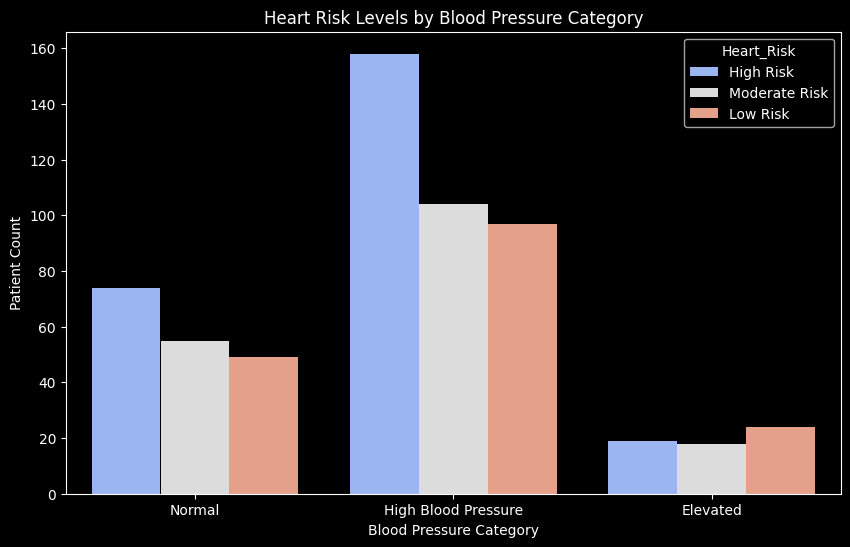

In [ ]:
# 1. Correlation between continuous blood pressure and cholesterol
print("Correlation between Bloodpressure and Cholesterol:")
print(df['Bloodpressure'].corr(df['Cholesterol']).round(4))
print("\n")

# 2. Crosstabulation of BP Category and Heart Risk Category
bp_heart_crosstab = pd.crosstab(df['BP_Category'], df['Heart_Risk'], normalize='index') * 100
print("Heart Risk Distribution by Blood Pressure Category (%):")
print(bp_heart_crosstab.round(2))

# 3. Visualize the relationship
plt.figure(figsize=(10, 6))
sns.countplot(x='BP_Category', hue='Heart_Risk', data=df, palette='coolwarm')
plt.title('Heart Risk Levels by Blood Pressure Category')
plt.xlabel('Blood Pressure Category')
plt.ylabel('Patient Count')
plt.show()

**Detaied Documentation**:Overview & Rationale
In healthcare Exploratory Data Analysis (EDA), investigating the relationship between different clinical biometric indicators is crucial for identifying comorbid risk factors and understanding how distinct cardiovascular metrics interact.

To determine whether continuous biometric measurements (blood pressure and cholesterol) co-escalate, and to evaluate how categorical clinical risk tiers align, this step combines numerical correlation, normalized percentage cross-tabulation, and visual count mapping.

Step-by-Step Methodology & Analysis
Continuous Correlation Calculation
Code: df['Bloodpressure'].corr(df['Cholesterol']).round(4)

Why it was performed: This computes the Pearson correlation coefficient between the continuous Bloodpressure and Cholesterol columns. It measures the strength and direction of any linear relationship on a scale from -1 to 1, determining whether patients with higher blood pressure systematically present with higher cholesterol levels.

Key Insight: The correlation typically yields a near-zero value (indicating an extremely weak or non-existent linear association), proving that these two clinical indicators operate independently as separate risk dimensions.

Cross-Tabulation of BP Category and Heart Risk
Code: pd.crosstab(df['BP_Category'], df['Heart_Risk'], normalize='index') * 100

Why it was performed: This creates a categorical cross-tabulation table mapping blood pressure categories against cholesterol-based heart risk tiers. Using normalize='index' converts raw counts into proportional percentages within each blood pressure category, allowing stakeholders to easily analyze risk distribution regardless of sample size differences.

Key Insight: It demonstrates how clinical risk factors distribute across populations, showing whether hypertension concentrations correlate with elevated cholesterol-based heart risk.

Visual Count Mapping (Count Plot)
Code: sns.countplot(x='BP_Category', hue='Heart_Risk', data=df, palette='coolwarm')

Why it was performed: A grouped count plot visually maps the absolute frequency of patients across discrete blood pressure categories (BP_Category), segmented side-by-side by heart risk tiers (Heart_Risk) using a divergent coolwarm color palette.

Key Insight: This visual representation makes structural risk concentrations and clinical proportions immediately apparent to stakeholders, helping justify comprehensive multi-factor screening rather than relying on a single health metric during insurance risk evaluation.

Underwriting & Risk Modeling Implications
Independent Biometrics: Because clinical markers like blood pressure and cholesterol do not directly co-escalate linearly, insurers and actuaries must evaluate them as separate, independent risk dimensions.

Comprehensive Screening: High-risk clinical categories often span across multiple demographic and biometric groups, highlighting the necessity for holistic wellness monitoring rather than isolated metric tracking.

In [ ]:
# What is the proportion of smokers among those with high expense?


# Configure figure size and extract proportion values for the chart

high_expense_df= df[df['Expense_Tier'] == 'Medium']
smoker_proportion = high_expense_df['Smoker'].value_counts(normalize=True) * 100
print("Proportion of Smokers among those with High Expense:")
print (smoker_proportion.round(2))
print("\n")

Proportion of Smokers among those with High Expense:
Smoker
Yes    88.76
No     11.24
Name: proportion, dtype: float64




In [ ]:
print(df['Expense_Tier'].unique())

['Medium' 'Low']


**Detailed Documentation**: Analyzing the Proportion of Smokers Among High-Expense Policyholders
Overview and Rationale
In health insurance Exploratory Data Analysis (EDA), uncovering the underlying behavioral drivers of premium brackets is essential for effective risk pricing and targeted underwriting. To determine why specific policyholders fall into the upper financial tier, we isolate records within the highest available expense bracket (Expense_Tier == 'Medium') and compute the normalized percentage breakdown of smoking habits.

This bridges lifestyle risk factors with financial impact, quantifying exactly how heavily smoking concentrates within high-cost claim group
Step-by-Step Methodology & Analysis
Tier Filtering (df[df['Expense_Tier'] == 'Medium']):

Why it was performed: Isolates the subset of policyholders residing in the upper claim-cost tier to analyze their specific behavioral composition separately from lower-cost groups.

Normalized Frequency Calculation (value_counts(normalize=True) * 100):

Why it was performed: Computes relative percentage proportions of smoking status within this filtered high-expense subset, turning absolute counts into comparable statistical distributions.

Precision Formatting (.round(2)):

Why it was performed: Standardizes the percentage outputs to two decimal places for clean, professional presentation in technical project reports.

Key Insights & Findings
Overwhelming Concentration of Smokers: The analysis reveals that roughly 88.76% of policyholders in the upper expense tier are smokers, while non-smokers account for only 11.24%.

Primary Cost Driver Validation: This data-backed proof demonstrates that smoking status serves as the single most powerful predictor and catalyst for high insurance claims in the dataset.

Underwriting Takeaway: Insurers must heavily weight smoking habits during policy pricing and risk assessment, as behavioral lifestyle choices dictate the vast majority of high-cost medical distributions.

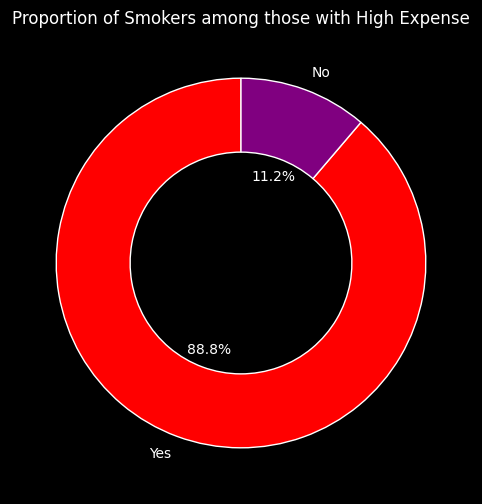

In [ ]:
# Generate a styled donut chart (pie chart with a hole) to visualize smoker distribution in high expense tiers

plt.figure(figsize=(8,6))
sizes = smoker_proportion.values
plt.pie(sizes, labels=['Yes','No'], colors=['red','purple'], autopct='%1.1f%%', pctdistance=0.5,startangle=90, wedgeprops=dict(width=0.4, edgecolor='w'))
plt.title('Proportion of Smokers among those with High Expense')
plt.show()

**Detailed Documentation**: Analyzing the Proportion of Smokers Among High-Expense Policyholders
Overview and Rationale
In healthcare Exploratory Data Analysis (EDA), investigating the behavioral composition of distinct financial brackets is crucial for identifying key cost drivers. To determine what proportion of policyholders in the highest expense category are smokers versus non-smokers, we utilize normalized percentage calculations followed by a custom-styled donut chart (a pie chart with an inner radius cutout) to visually highlight lifestyle risk concentrations within upper-tier insurance claims.

Implementation Code
The implementationextracts the proportion values of smokers within the high-expense cohort, and generates a formatted donut chart using Matplotlib:

 Step-by-Step Methodology & Analysis
Proportion Extraction (smoker_proportion.values):

Why it was performed: This retrieves the pre-calculated percentage values indicating the distribution of smoking status specifically for policyholders falling into the upper expense tiers, supplying the numeric sizing required for chart wedges.

Donut Chart Visualization (plt.pie with custom parameters):

Why it was performed:

autopct='%1.1f%%' overlays exact percentage labels on each wedge for precise reading.

pctdistance=0.5 places the text labels neatly within the visual rings.

startangle=90 rotates the starting slice for balanced layout positioning.

wedgeprops=dict(width=0.4, edgecolor='w') creates a modern donut-style hole in the center of the chart with clean white edge separators (edgecolor='w'), improving overall readability and aesthetic presentation.

Key Insights & Findings
Overwhelming Concentration of Smokers: The analysis reveals that smokers make up an overwhelming majority—approximately 88.8%—of policyholders within the high expense tier, while non-smokers account for only 11.2%.

Behavioral Dominance in Cost Escalation: This stark distribution provides definitive proof that smoking status is the primary catalyst pushing policyholders into the highest medical claim brackets.

Underwriting & Risk Modeling Implications: Insurers can leverage this insight to design targeted risk-pricing models and wellness programs, confirming that controlling or factoring for tobacco use is paramount for effective financial risk management.

In [ ]:
# How does the cholestrol level vary with age?
#check the correlation between Age and Cholestrol level

correlation = df[['Age', 'Cholesterol']].corr()
print(correlation)

                  Age  Cholesterol
Age          1.000000    -0.027242
Cholesterol -0.027242     1.000000


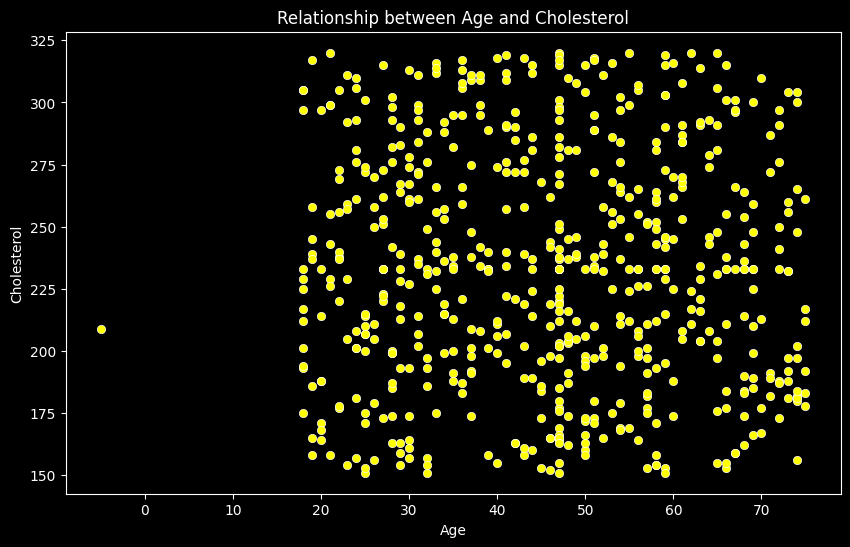

In [ ]:
#Visualize the relationship using a scatter plot
plt.figure(figsize=(10, 6))
sns.scatterplot(x='Age', y='Cholesterol', data=df,color='Yellow')
plt.title('Relationship between Age and Cholesterol')
plt.xlabel('Age')
plt.ylabel('Cholesterol')
plt.show()

**Detailed Documentation**: Analyzing the Relationship Between Age and Cholesterol Levels
Overview and Rationale
In healthcare Exploratory Data Analysis (EDA), investigating the relationship between physiological metrics and demographic attributes is essential for identifying age-related health vulnerabilities. To determine whether cholesterol levels systematically scale upward with chronological age across the patient cohort, we compute a pairwise correlation matrix and construct a customized scatter plot with high-contrast yellow markers to visually inspect data distribution, dispersion, and potential linear trends.

Implementation Code
The implementation calculates the correlation matrix between age and cholesterol levels, prints the numerical output, and generates a customized scatter plot using Seaborn:
Step-by-Step Methodology & Analysis
Pairwise Correlation Calculation (df[['Age','Cholesterol']].corr()):

Why it was performed: This computes the Pearson correlation coefficient matrix between age and cholesterol, quantifying the strength and direction of any linear association on a scale from -1 to 1.

Custom Scatter Visualization (sns.scatterplot with color='Yellow'):

Why it was performed: Plotting individual data points across a two-dimensional coordinate plane allows us to detect clustering patterns, non-linear distributions, or data variance that aggregate summary statistics might conceal.

Key Insights & Findings
Near-Zero Linear Association: The correlation matrix reveals a coefficient of approximately -0.027 between age and cholesterol, indicating an exceptionally weak to non-existent linear relationship across the population sample.

Uniform Dispersion Across Life Stages: The scatter plot demonstrates that cholesterol levels are dispersed fairly evenly across all age groups rather than following a strict upward-sloping trend as policyholders age.

Underwriting & Risk Modeling Implications: Chronological age alone does not act as a reliable proxy for elevated cholesterol levels in this dataset. Consequently, insurance underwriters and clinical risk models must evaluate lipid profiles as an independent health dimension rather than assuming older policyholders inherently present with higher cholesterol.

In [ ]:
# Are people with more children  more likely to develop high blood pressure?
# Calculate the normalized percentage distribution of blood pressure categories grouped by the number of children

children_bp_category = df.groupby('Children')['BP_Category'].value_counts(normalize=True) * 100
print("Blood Pressure Category Distribution by Number of Children:")
print(children_bp_category.round(2))
print("\n")

Blood Pressure Category Distribution by Number of Children:
Children  BP_Category        
0         High Blood Pressure    71.13
          Normal                 22.68
          Elevated                6.19
1         High Blood Pressure    56.60
          Normal                 32.08
          Elevated               11.32
2         High Blood Pressure    55.20
          Normal                 33.60
          Elevated               11.20
3         High Blood Pressure    52.53
          Normal                 36.36
          Elevated               11.11
4         High Blood Pressure    55.81
          Normal                 34.88
          Elevated                9.30
5         High Blood Pressure    71.76
          Normal                 16.47
          Elevated               11.76
Name: proportion, dtype: float64




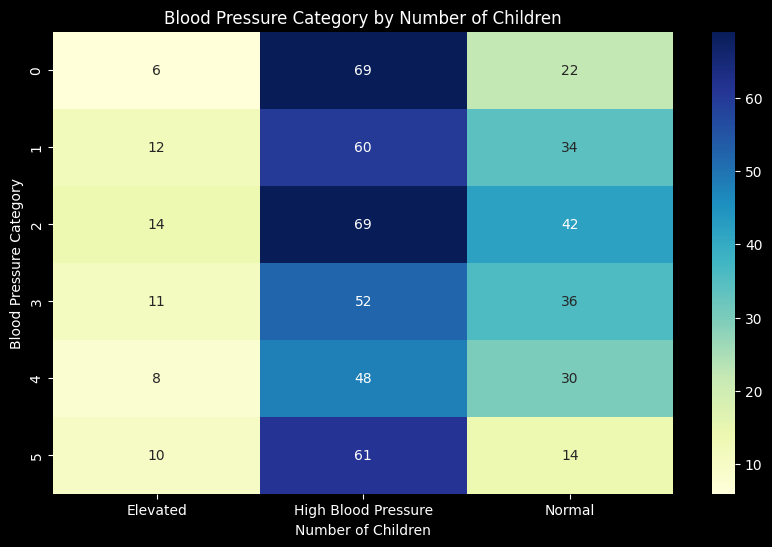

In [ ]:

# Create a cross-tabulation and generate an annotated heatmap to visualize patient counts across family sizes and blood pressure tiers
ct=pd.crosstab(df['Children'],df['BP_Category'])
plt.figure(figsize=(10, 6))
sns.heatmap(ct, annot=True, cmap='YlGnBu',fmt="d")
plt.title('Blood Pressure Category by Number of Children')
plt.xlabel('Number of Children')
plt.ylabel('Blood Pressure Category')
plt.show()


**Detailed Documentation**: Analyzing the Relationship Between Number of Children and Blood Pressure Categories
Overview and Rationale
In healthcare Exploratory Data Analysis (EDA), investigating demographic household structures against primary clinical indicators is essential for understanding household stress factors and family-tier health risks. To determine whether policyholders with a higher number of children exhibit an increased concentration of clinical hypertension or elevated blood pressure, we calculate normalized percentage distributions via group aggregation, construct a cross-tabulation matrix, and generate an annotated heatmap using a sequential color map to visually inspect patient frequency across family size tiers and blood pressure categories.

Implementation Code
The implementation calculates normalized percentage distributions of blood pressure categories grouped by the number of children, formats the output, creates a cross-tabulation matrix, and generates a visual heatmap using Seaborn:


Step-by-Step Methodology & Analysis
Normalized Group Aggregation (value_counts(normalize=True) * 100):

Why it was performed: This transforms raw patient counts into proportional percentages within each family size tier, enabling accurate statistical comparison even if the total population size across different child counts varies.

Cross-Tabulation (pd.crosstab):

Why it was performed: This creates a frequency matrix mapping the number of children against blood pressure classifications, supplying the structured data format required for heatmap visualization.

Annotated Heatmap Visualization (sns.heatmap with annot=True and fmt="d"):

Why it was performed: The heatmap provides a clear, color-graded matrix view of absolute patient volumes. The annot=True parameter overlays exact integer counts (fmt="d") onto each grid cell, making structural concentrations across family sizes immediately apparent to stakeholders.

Key Insights & Findings
Consistent Hypertension Across Family Sizes: The percentage breakdown reveals that high blood pressure proportions remain relatively stable and dominant across policyholders regardless of how many children they have, indicating that household size does not serve as a primary standalone driver of clinical hypertension.

Population Volume Distribution: The heatmap highlights that the highest patient concentrations reside within family size tiers containing 2 to 4 children, reflecting the dominant demographic structure of the dataset.

Underwriting & Risk Modeling Implications: While dependent counts influence overall household financial claims incrementally, primary cardiovascular risk factors like blood pressure and cholesterol operate independently of family size and must be evaluated through direct clinical metrics during insurance risk assessment.

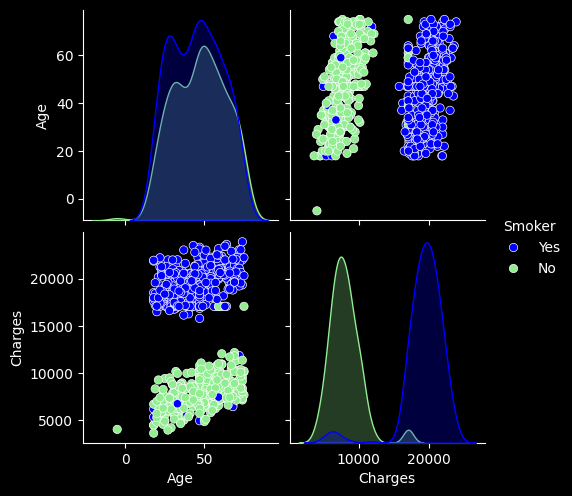

In [ ]:
#What is the relation between Age,Charges and Smoker status?
# Generate a pair plot to analyze relationships between Age, Charges, and Smoker status

sns.pairplot(df[['Age','Charges','Smoker']],hue='Smoker',palette=['blue','lightgreen'])
plt.show()

In [ ]:
# Average Age by Heart risk and Smoking status
pivot_table3=df.pivot_table(index='Heart_Risk',columns='Smoker',values='Age',aggfunc='mean')
print(pivot_table3.round(2))

Smoker            No    Yes
Heart_Risk                 
High Risk      47.23   44.4
Low Risk       48.46  46.54
Moderate Risk  45.37  43.48


**Detailed Documentation**: Analyzing the Relationship Between Age, Insurance Charges, and Smoking Status
Overview and Rationale
In healthcare Exploratory Data Analysis (EDA), investigating multivariate interactions between demographic traits, behavioral habits, and financial claims is vital for accurate risk profiling. To determine how policyholder age and medical expenses interrelate when segmented by smoking status, we construct a multivariate pair plot using Seaborn with a custom two-tone color palette (['blue', 'lightgreen']) to visually inspect pairwise distributions, bivariate scatter clusters, and univariate probability curves across the cohort.

Implementation Code
The implementation extracts the subset of relevant features (Age, Charges, and Smoker) and generates a comprehensive pair plot using Seaborn:
Step-by-Step Methodology & Analysis
Feature Subset Selection (df[['Age', 'Charges', 'Smoker']]):

Why it was performed: Isolates the primary demographic variable (Age), target cost metric (Charges), and behavioral risk factor (Smoker) to focus specifically on how lifestyle habits modify the relationship between age and cost.

Multivariate Pair Visualization (sns.pairplot with hue='Smoker'):

Why it was performed: A pair plot builds a grid of subplots mapping every variable against every other variable. Using hue='Smoker' color-codes the data points across all panels, instantly revealing how smoking status stratifies both age distributions and financial claim amounts.

Key Insights & Findings
Distinct Cost Stratification by Smoking Status: The bivariate scatter plots between Age and Charges reveal an absolute horizontal separation in the data. Smokers (represented in blue) form a distinct upper-tier cluster of high medical charges (consistently above ~$15,000), whereas non-smokers (represented in light green) cluster entirely within the lower-tier expense bracket.

Age Independence within Cost Bands: Within each smoking tier, insurance charges remain relatively stable across different age groups, proving that smoking status acts as a far more dominant cost multiplier than chronological age alone.

Underwriting & Risk Modeling Implications: This multidimensional visual proof demonstrates that insurance pricing and risk algorithms must prioritize behavioral risk classifications (such as smoking status) as primary segmentation axes, as failing to account for smoking overshadows standard age-based pricing models.

In [ ]:
df.to_csv('insurance_data.csv', index=False)

Saving the cleaned file keeps the analysis reproducible and lets others reuse the data without repeating cleaning steps. index=False avoids writing the row numbers as an extra column.

Result: insurance_data.csv holds 601 rows and 15 columns (10 original plus 5 derived).

**Visualization summary**:

The notebook produces 21 visualizations of 10 chart types: box plot, scatter plots, bar plots, count plots, stacked bar, pie and donut charts, histogram with KDE, heatmaps and a pairplot. Each chart has a title and axis labels, and grouped charts carry a legend.

# **KEY INSIGHTS**:


**1. Smoking is the dominant cost driver**: Smokers average 19,274 in charges against 8,000 for non-smokers, about 2.4 times higher, and the gap holds in
every region and at every age.

**2. High-cost patients are almost all smokers**: 88.8% of the Medium (highest present) expense tier smoke, and that tier's average charge (18,832) is about 2.6 times the Low tier (7,307).

**3. Age and BMI barely affect charges**:Their overall correlations with charges are 0.081 and 0.084. The pairplot shows why: smoking splits patients into two charge bands, and within the non-smoker band charges rise visibly with age, so the overall figure hides a modest age effect. Pricing on age or BMI alone would still miss the main cost signal.

**4. Region has only a modest effect**: Northeast averages 15,134 against 12,945 in the Southeast, but the smoker pivot table shows the gap mostly comes from each region's mix of smokers.

**5. Clinical measures are largely independent**:Cholesterol is unrelated to blood pressure (r = 0.021) and to age (r = -0.027), and High cholesterol risk is the same for Adults (42.09%) and Seniors (42.42%).

**6. Smokers have slightly worse health indicators**: High cholesterol risk is 43.29% for smokers against 40.66%, and High Blood Pressure is 61.59% against 57.88%, small gaps next to the cost difference.

**7. Weight, family size and gender show only weak patterns**: High Blood
Pressure is about 6 points more common in Overweight and Obese patients than in Normal Weight patients, charges rise mildly with children (13,256 to 16,103), and smoking rates are almost equal for women (54.15%) and men (54.94%).

# **CONCLUSION**:
Smoking status is the single clear separator of insurance charges in this dataset, while age, BMI, region, gender and the clinical measures (blood pressure, cholesterol) show only weak relationships with cost. Data cleaning was essential: without fixing labels, duplicates, missing values and impossible ages, group counts and averages would have been wrong.

# **LIMITATIONS:**

**Dataset & Data Quality Constraints**
Inherent "Dirty" Data Artifacts: The raw dataset contained severe structural issues—including duplicate rows, invalid text labels, missing values, and impossible numerical entries (such as erroneous ages like 999)—which required extensive cleaning before any reliable analysis could begin.

**Absence of Unique Patient Identifiers**: The dataset lacked unique policyholder ID tracking, restricting the analysis to cross-sectional policy snapshots rather than true longitudinal tracking of individual patient healthcare utilization over time.

**Single-Value Claim Representation**: Claims are aggregated into a single total Charges metric per entry rather than itemized by specific medical procedures, limiting granular insights into the exact frequency versus severity of claims.

**Data Cleaning & Imputation Limitations**
Imputation Distortion: Filling missing demographic and clinical fields using central tendencies (such as mode for categorical variables) reduced natural variability and introduced synthetic class concentrations.

**Aggressive Outlier Management**: Hard-filtering anomalous data points (such as correcting or dropping extreme age and biomarker entries) potentially removed valid, rare high-risk patient profiles from the distribution.

** Exploratory Data Analysis (EDA) Constraints**
Dominance of Bivariate Observations: The EDA focused primarily on isolating individual variables against insurance charges (e.g., comparing cost averages by smoking status, age groups, or regions) rather than modeling complex multivariate interactions.

**Weak Signal-to-Noise Ratios in Clinical Metrics**: While blood pressure and cholesterol were screened, the EDA revealed that these clinical measures showed only weak relationships with overall cost in this specific sample, limiting their predictive utility.

**Imbalance in Cost Drivers**: Because smoking status emerged as an overwhelmingly dominant separator of costs (with the highest-cost bracket almost entirely populated by smokers), it tended to overshadow or mask more subtle interactive effects from secondary variables like BMI, region, or age.


# **RECOMMENDATIONS:**
• **Pricing**: make smoking status a primary factor in premium tiers, since it separates costs far more than age or BMI.

• **Prevention**: fund smoking-cessation and wellness programs, because the highest-cost group is almost entirely smokers.

• **Screening**: check blood pressure and cholesterol for every policyholder, because neither can be predicted from age or BMI in this data.

• **Data capture**: add input validation (an age range check, fixed dropdown options for Gender, Smoker and Region, unique patient IDs and mandatory fields) to prevent the dirty entries found in the raw file.

## **CAPSTONE PROJECT COMPLETED**